In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

import dask

os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

dask.config.set({"logging.distributed": "error"})
dask.config.set(num_workers=15, threads_per_worker=16)
dask.config.set({"array.chunk-size": "400MiB"})

In [3]:
import json
from pathlib import Path

import dask
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import rioxarray as rxr
import seaborn as sns
import xarray as xr
from dask.diagnostics import ProgressBar
from rasterio.features import rasterize as rio_rasterize
from shapely.geometry import box as shapely_box

from cordex2energy.conversion_energy.disaggregate import disaggregate_dataset_radiation
from cordex2energy.results.plotting import plot_nodes_choropleth
from cordex2energy.utils.constants import REGRIDDED_CHUNKS, EXTENT_CH
from cordex2energy.utils.utils_xarray import sel_extent

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/cordex2energy/share/proj failed


In [4]:
paths = json.load(open("../../paths_so4.json"))

path_data_processed = Path(paths["path_data_processed"])
path_data_personal = Path(paths["path_data_personal"])
path_data_recipe = path_data_processed / "recipe"
path_ftp = Path("/net/exo/landclim_nobackup/FTP/yhaddad/recipe/")

path_energy_europe = path_data_processed / "energy" / "europe"

# Load data

In [5]:

climate_model = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

wind_turbine = "E-126_7580"

years = [2040, 2041]


In [6]:

# Regex pattern that matches any of the requested years in a column name
_year_pattern = "|".join(str(y) for y in years)

ds_pv = xr.open_zarr(
    path_energy_europe
    / "pv"
    / f"{climate_model}_{climate_scenario}"
    / f"pv_{climate_model}_{climate_scenario}.zarr"
).sel(time=slice(str(years[0]), str(years[-1])))
ds_wind = xr.open_zarr(
    path_energy_europe
    / "wind_power"
    / f"{climate_model}_{climate_scenario}"
    / f"wind_power_{climate_model}_{climate_scenario}_{wind_turbine}.zarr"
).sel(time=slice(str(years[0]), str(years[-1])))

path_c2e = path_data_processed / "c2e" / "outputs" / f"{'_'.join(climate_model.split('_')[:-1])}" / "output_variables"

df_hydro_ror = pd.read_csv(
    path_c2e
    / "hydro_ror_CORDEX_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_85.csv"
)
df_hydro_ror = df_hydro_ror.loc[
    :, ["country"] + df_hydro_ror.columns[df_hydro_ror.columns.str.contains(_year_pattern)].tolist()
]

df_hydro_inflow = pd.read_csv(
    path_c2e
    / "hydro_inflow_CORDEX_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_85.csv"
)
df_hydro_inflow = df_hydro_inflow.loc[
    :, ["country"] + df_hydro_inflow.columns[df_hydro_inflow.columns.str.contains(_year_pattern)].tolist()
]

df_heating_demand = pd.read_csv(path_c2e / "heating-demand_CORDEX_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_85_fully-electrified.csv")
df_heating_demand = df_heating_demand.loc[
    :, ["country"] + df_heating_demand.columns[df_heating_demand.columns.str.contains(_year_pattern)].tolist()
]

df_cooling_demand = pd.read_csv(path_c2e / "cooling-demand_CORDEX_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_85.csv")
df_cooling_demand = df_cooling_demand.loc[
    :, ["country"] + df_cooling_demand.columns[df_cooling_demand.columns.str.contains(_year_pattern)].tolist()
]


In [ ]:
sel_extent(ds_wind, EXTENT_CH).resample(time="YS").mean(dim="time")

SyntaxError: expected argument value expression (3489507484.py, line 1)

In [9]:
pop_path = path_data_processed / "pop" / "gpw_v4" / "gpw_v4_population_count_adjusted_to_2015_unwpp_country_totals_rev11_2020_30_sec.tif"
da_pop = rxr.open_rasterio(pop_path, masked=True)

In [10]:
pop_path = path_data_processed / "pop" / "gpw_v4" / "gpw_v4_population_count_adjusted_to_2015_unwpp_country_totals_rev11_2020_30_sec.tif"

lon_min = float(ds_pv.lon.min())
lon_max = float(ds_pv.lon.max())
lat_min = float(ds_pv.lat.min())
lat_max = float(ds_pv.lat.max())

da_pop = (
    rxr.open_rasterio(pop_path, masked=True)
    .squeeze("band", drop=True)
    .rio.clip_box(minx=lon_min, miny=lat_min, maxx=lon_max, maxy=lat_max)
)
da_pop.name = "pop_count"
da_pop.attrs["units"] = "persons"

print(da_pop)

<xarray.DataArray 'pop_count' (y: 5101, x: 8509)> Size: 174MB
[43404409 values with dtype=float32]
Coordinates:
  * x            (x) float64 68kB -29.95 -29.95 -29.94 ... 40.93 40.94 40.95
  * y            (y) float64 41kB 72.55 72.54 72.53 72.52 ... 30.06 30.05 30.05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:       Area
    DataType:            Generic
    RepresentationType:  ATHEMATIC
    scale_factor:        1.0
    add_offset:          0.0
    units:               persons


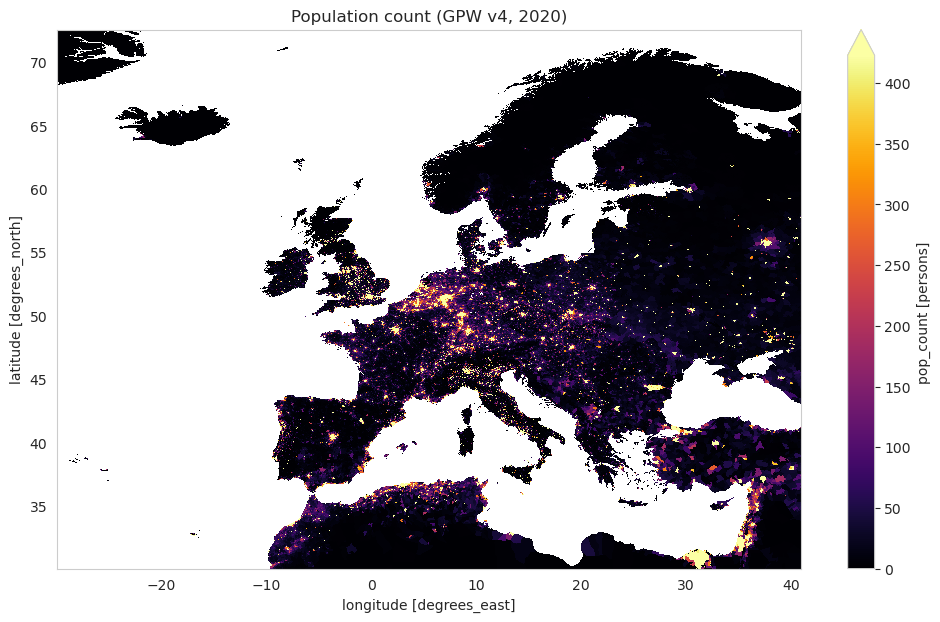

In [11]:
da_pop.plot(robust=True, cmap="inferno", figsize=(12, 7))
plt.title("Population count (GPW v4, 2020)")
plt.show()

In [12]:
df_hydropower_generators = pd.read_excel(path_data_recipe / "hydro_generators.xlsx")
df_hydropower_generators_ror = df_hydropower_generators.loc[
    df_hydropower_generators["Technology"].str.contains("Run-of-River", na=False)
    & df_hydropower_generators["Country"].isin(df_hydro_ror["country"])
].reset_index(drop=True)

df_hydropower_generators_storage = df_hydropower_generators.loc[
    ~df_hydropower_generators["Technology"].str.contains("Run-of-River", na=False)
    & df_hydropower_generators["Country"].isin(df_hydro_inflow["country"])
].reset_index(drop=True)

In [13]:
df_voronoi_nodes = pd.read_csv(path_data_recipe / "Node_demand_full.csv")
gdf_voronoi_nodes = gpd.GeoDataFrame(
    df_voronoi_nodes,
    geometry=gpd.GeoSeries.from_wkt(df_voronoi_nodes["geometry"]),
    crs="EPSG:4326",
)

_extent = shapely_box(
    float(ds_pv.lon.min()), float(ds_pv.lat.min()),
    float(ds_pv.lon.max()), float(ds_pv.lat.max()),
)
gdf_voronoi_nodes = gdf_voronoi_nodes[gdf_voronoi_nodes.geometry.within(_extent)].reset_index(drop=True)


In [14]:
nodes_regions = regionmask.Regions(
    name="nodes",
    numbers=range(len(gdf_voronoi_nodes)),
    names=gdf_voronoi_nodes["BUS_I"],
    outlines=gdf_voronoi_nodes.geometry.values,
)
mask_nodes = nodes_regions.mask(ds_pv.isel(time=0))
mask_nodes.name = "node"
mask_nodes.attrs["long_name"] = "Node mask"

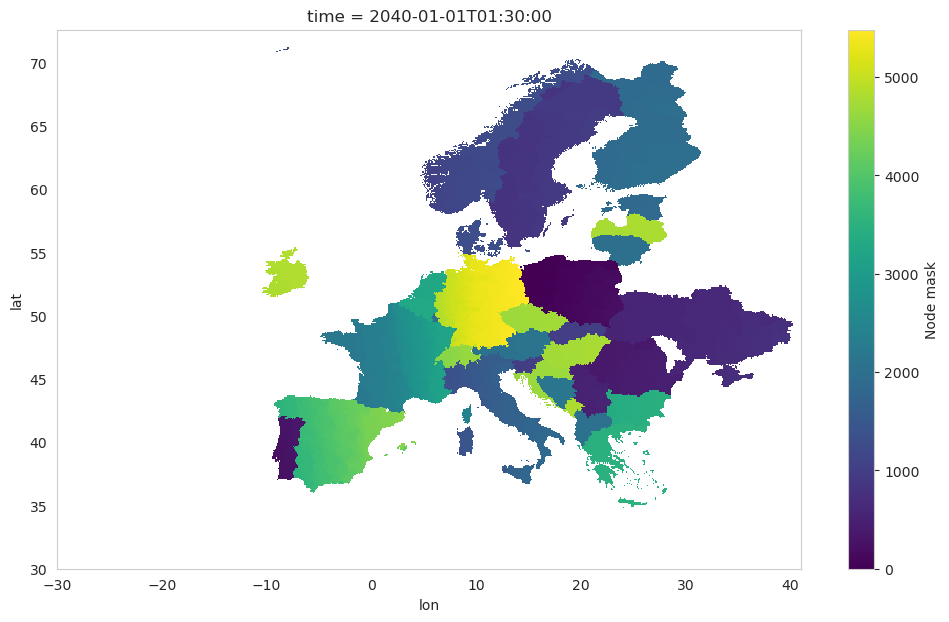

In [15]:
mask_nodes.plot(figsize=(12, 7), add_colorbar=True)

In [16]:
df_voronoi_nodes_wind = pd.read_csv(path_data_recipe / "Node_voronoi_cleaned.csv")
gdf_voronoi_nodes_wind = gpd.GeoDataFrame(
    df_voronoi_nodes_wind,
    geometry=gpd.GeoSeries.from_wkt(df_voronoi_nodes_wind["geometry"]),
    crs="EPSG:4326",
)

_extent = shapely_box(
    float(ds_pv.lon.min()), float(ds_pv.lat.min()),
    float(ds_pv.lon.max()), float(ds_pv.lat.max()),
)
gdf_voronoi_nodes_wind = gdf_voronoi_nodes_wind[gdf_voronoi_nodes_wind.geometry.within(_extent)].reset_index(drop=True)


In [17]:
nodes_wind_regions = regionmask.Regions(
    name="nodes",
    numbers=range(len(gdf_voronoi_nodes_wind)),
    names=gdf_voronoi_nodes_wind["BUS_I"],
    outlines=gdf_voronoi_nodes_wind.geometry.values,
    overlap=False
)
mask_nodes_wind = nodes_wind_regions.mask(ds_pv.isel(time=0))
mask_nodes_wind.name = "node"
mask_nodes_wind.attrs["long_name"] = "Node wind mask"

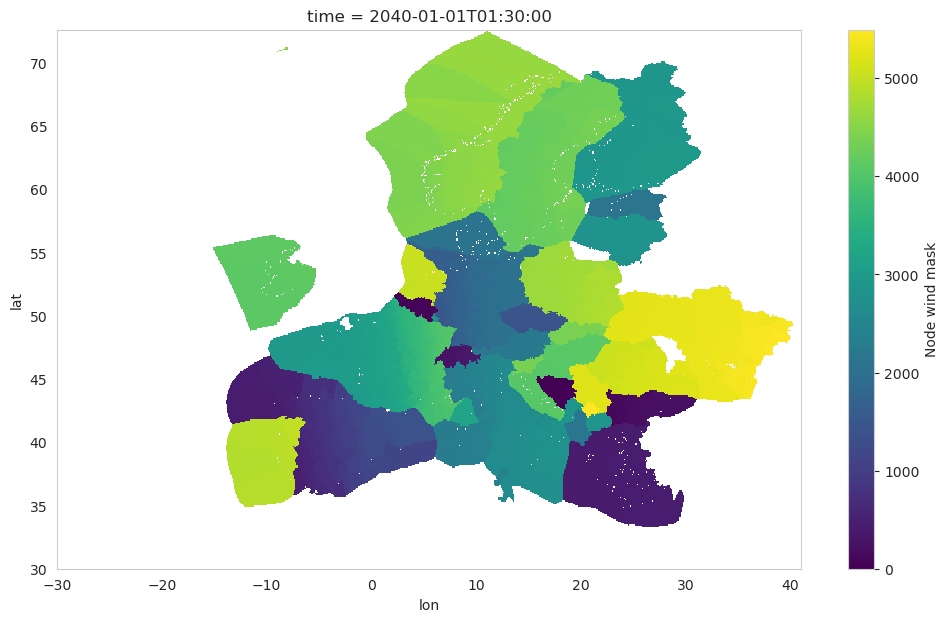

In [18]:
mask_nodes_wind.plot(figsize=(12, 7), add_colorbar=True)

# PV

## PV disaggregation: 3-hourly → hourly (scipy cubic spline)

The 3-hourly PV output is disaggregated to hourly resolution using
bias-corrected rsds as radiation weights.  The **scipy** method fits a global
`CubicSpline` over the time axis, so the data must be rechunked to
`REGRIDDED_CHUNKS` (`time=-1`, small spatial tiles) before the call.
The result is then available at hourly resolution, ready for node aggregation.

In [19]:
# --- Load bias-corrected rsds for the same model / scenario / time window ---
rsds_3h = xr.open_zarr(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "rsds.zarr",
    chunks="auto",
)["rsds"].sel(time=slice(str(years[0]), str(years[-1])))

# Align rsds lat/lon to PV grid (they may differ by small floating-point offsets)
pv_ref = ds_pv[list(ds_pv.data_vars)[0]]
rsds_3h = rsds_3h.sel(
    lat=pv_ref.lat,
    lon=pv_ref.lon,
    method="nearest",
    tolerance=0.05,
)

print("PV  :", ds_pv)
print("\nrsds:", rsds_3h)

PV  : <xarray.Dataset> Size: 7GB
Dimensions:            (lat: 426, lon: 710, time: 5840)
Coordinates:
  * lat                (lat) float64 3kB 30.05 30.15 30.25 ... 72.35 72.45 72.55
  * lon                (lon) float64 6kB -29.95 -29.85 -29.75 ... 40.85 40.95
  * time               (time) datetime64[ns] 47kB 2040-01-01T01:30:00 ... 204...
Data variables:
    tilt_35_azimuth_S  (time, lat, lon) float32 7GB dask.array<chunksize=(2920, 128, 128), meta=np.ndarray>

rsds: <xarray.DataArray 'rsds' (time: 5840, lat: 426, lon: 710)> Size: 7GB
dask.array<getitem, shape=(5840, 426, 710), dtype=float32, chunksize=(2920, 128, 128), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 3kB 30.05 30.15 30.25 30.35 ... 72.35 72.45 72.55
  * lon      (lon) float64 6kB -29.95 -29.85 -29.75 -29.65 ... 40.75 40.85 40.95
  * time     (time) datetime64[ns] 47kB 2040-01-01T01:30:00 ... 2041-12-31T22...
Attributes:
    bias_adjustment:     EmpiricalQuantileMapping(group=Grouper(name='time.da...
 

In [20]:
# --- Disaggregate 3-hourly PV → hourly using scipy cubic spline ---
# The scipy method requires time=-1 (full time axis in one Dask chunk).
# Both datasets are rechunked to REGRIDDED_CHUNKS before the call.
# For a single month this is lightweight (~240 timesteps × 20×20 spatial tiles).

ds_pv_rechunked = ds_pv.chunk(REGRIDDED_CHUNKS)
rsds_3h_rechunked = rsds_3h.chunk(REGRIDDED_CHUNKS)

print(f"Rechunked to REGRIDDED_CHUNKS={REGRIDDED_CHUNKS}")
print("Running disaggregation (scipy) …")

with ProgressBar():
    ds_pv_hourly = disaggregate_dataset_radiation(
        ds_pv_rechunked,
        rsds_3h_rechunked,
        method="scipy",
        threshold=5.0,
    ).compute()

print("\nHourly PV dataset:")
print(ds_pv_hourly)

Rechunked to REGRIDDED_CHUNKS={'time': -1, 'lat': 20, 'lon': 20}
Running disaggregation (scipy) …
[####################################### ] | 99% Completed | 37.28 ss

[########################################] | 100% Completed | 37.38 s

Hourly PV dataset:
<xarray.Dataset> Size: 42GB
Dimensions:            (lat: 426, lon: 710, time: 17520)
Coordinates:
  * lat                (lat) float64 3kB 30.05 30.15 30.25 ... 72.35 72.45 72.55
  * lon                (lon) float64 6kB -29.95 -29.85 -29.75 ... 40.85 40.95
  * time               (time) datetime64[ns] 140kB 2040-01-01T00:30:00 ... 20...
Data variables:
    tilt_35_azimuth_S  (lat, lon, time) float64 42GB 0.0 0.0 0.0 ... 0.0 0.0 0.0


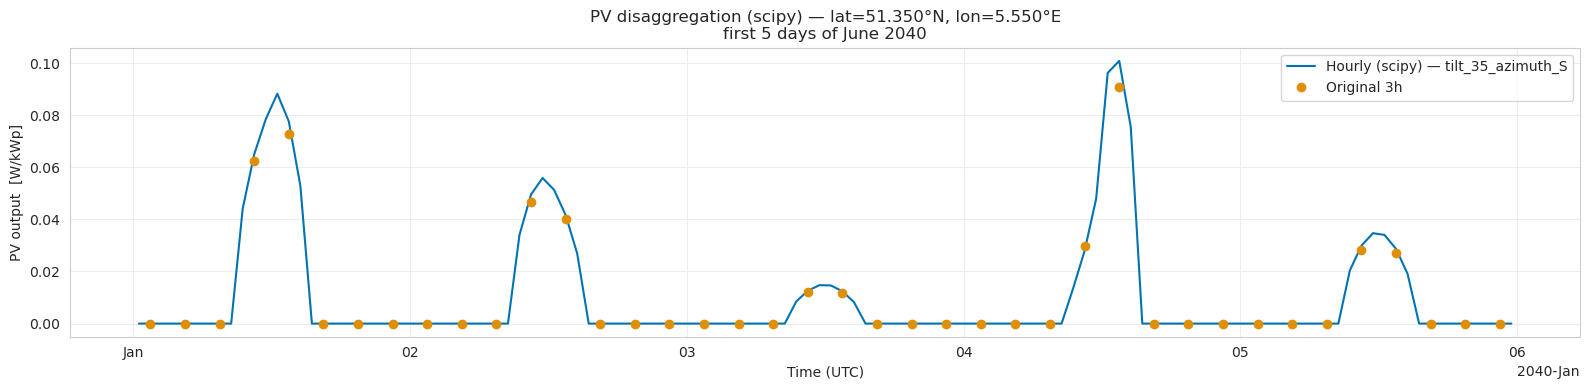

In [21]:
# --- Quick sanity plot: 3h vs hourly for one grid point and one variable ---
var_name = list(ds_pv_hourly.data_vars)[0]
i_lat, i_lon = (
    ds_pv_hourly[var_name].sizes["lat"] // 2,
    ds_pv_hourly[var_name].sizes["lon"] // 2,
)

pv_1h_pt = ds_pv_hourly[var_name].isel(lat=i_lat, lon=i_lon)
pv_3h_pt = ds_pv[var_name].isel(lat=i_lat, lon=i_lon)

n_days = 5
t0 = pd.Timestamp(str(pv_1h_pt.time.values[0])).floor("D")
t1 = t0 + pd.Timedelta(days=n_days)

fig, ax = plt.subplots(figsize=(16, 4))
pv_1h_pt.sel(time=slice(t0, t1)).plot(
    ax=ax, lw=1.5, label=f"Hourly (scipy) — {var_name}"
)
pv_3h_pt.sel(time=slice(t0, t1)).plot(
    ax=ax, marker="o", ms=6, lw=0, color="C1", label="Original 3h", zorder=5
)
ax.set_title(
    f"PV disaggregation (scipy) — "
    f"lat={float(pv_1h_pt.lat):.3f}°N, lon={float(pv_1h_pt.lon):.3f}°E\n"
    f"first {n_days} days of June 2040"
)
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("PV output  [W/kWp]")
ax.legend()
plt.tight_layout()
plt.show()

In [22]:
ds_pv_grouped = ds_pv_hourly.groupby(mask_nodes).mean(dim=["lat", "lon"], skipna=True)

In [23]:
ds_pv_grouped

<xarray.Dataset> Size: 678MB
Dimensions:            (time: 17520, node: 4835)
Coordinates:
  * time               (time) datetime64[ns] 140kB 2040-01-01T00:30:00 ... 20...
  * node               (node) float64 39kB 0.0 1.0 2.0 ... 5.481e+03 5.482e+03
Data variables:
    tilt_35_azimuth_S  (time, node) float64 678MB 0.0 0.0 0.0 ... 0.0 0.0 0.0

# Wind power

In [24]:
ds_wind_1h = ds_wind.resample(time="h").interpolate("linear")
with ProgressBar(dt=1):
    ds_wind_grouped = (
        ds_wind_1h.groupby(mask_nodes_wind).mean(dim=["lat", "lon"], skipna=True).compute()
    )

/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/util/deprecation_helpers.py:143: PerformanceWarning: Reshaping is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array.reshape(shape)

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array.reshape(shape)Explicitly passing ``limit`` to ``reshape`` will also silence this warning
    >>> array.reshape(shape, limit='128 MiB')
  return func(*args, **kwargs)


[                                        ] | 0% Completed | 190.98 us

/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/flox/core.py:2684: PerformanceWarning: Slicing with an out-of-order index is generating 26 times more chunks
  result = result[..., sorted_idx]


[########################################] | 100% Completed | 62.15 s


In [25]:
ds_wind_grouped

<xarray.Dataset> Size: 688MB
Dimensions:     (time: 17542, node: 4899)
Coordinates:
  * time        (time) datetime64[ns] 140kB 2040-01-01 ... 2041-12-31T21:00:00
  * node        (node) float64 39kB 0.0 1.0 2.0 ... 5.493e+03 5.494e+03
Data variables:
    E-126_7580  (time, node) float64 688MB 0.02576 0.009733 ... 0.09383 0.1132

# Hydropower

## Run-of-river

### Per power plant

In [26]:
# --- Filter run-of-river generators and compute capacity weights ---
ror_gen = df_hydropower_generators_ror.copy()

# Drop plants with missing or zero capacity — they cannot receive a share
n_before = len(ror_gen)
ror_gen = ror_gen.dropna(subset=["Capacity"])
ror_gen = ror_gen[ror_gen["Capacity"] > 0].reset_index(drop=True)
n_dropped = n_before - len(ror_gen)
if n_dropped:
    print(f"Dropped {n_dropped} plant(s) with NaN / zero capacity.")

# Weight of each plant = its capacity / total ROR capacity in its country
ror_gen["weight"] = ror_gen["Capacity"] / ror_gen.groupby("Country")["Capacity"].transform("sum")

# Verify: weights must sum to 1.0 per country
weight_sums = ror_gen.groupby("Country")["weight"].sum()
assert (weight_sums - 1.0).abs().max() < 1e-10, f"Weights don't sum to 1:\n{weight_sums}"

print(f"ROR generators: {len(ror_gen)} plants across {ror_gen['Country'].nunique()} countries")
ror_gen[["Name", "Country", "Capacity", "weight"]].head(10)

ROR generators: 1497 plants across 6 countries


,Name,Country,Capacity,weight
0,Abwinden Asten,Austria,168.0,0.034203
1,Alberschwende,Austria,30.0,0.006108
2,Altenmarkt,Austria,26.0,0.005293
3,Altenworth,Austria,328.0,0.066777
4,Amlach,Austria,60.0,0.012215
5,Annabrucke,Austria,90.0,0.018323
6,Aschach,Austria,287.4,0.058512
7,Bischofshofen,Austria,16.0,0.003257
8,Bodendorf Mur,Austria,7.0,0.001425
9,Braunau Simbach,Austria,100.0,0.020359


In [27]:

# --- Distribute country-level ROR generation to individual plants ---
# df_hydro_ror: wide format  →  rows = countries, cols = daily timesteps
# Result: wide format  →  rows = plant names (index), cols = daily timesteps

# Preserve original column order (do NOT use .difference() which sorts alphabetically)
time_cols = [c for c in df_hydro_ror.columns if c != "country"]
ror_country_ts = df_hydro_ror.set_index("country")[time_cols]

# Merge each plant's weight onto the country time series, then scale
merged = (
    ror_gen[["Name", "Country", "weight"]]
    .merge(ror_country_ts, left_on="Country", right_index=True, how="left")
    .set_index("Name")
)
df_ror_plants = merged[time_cols].multiply(merged["weight"], axis=0)

# Plants whose country has no time series get NaN rows — report them
missing = df_ror_plants.isna().all(axis=1)
if missing.any():
    print(f"Warning: {missing.sum()} plants have no matching country in df_hydro_ror:")
    print(ror_gen.loc[ror_gen["Name"].isin(missing[missing].index), ["Name", "Country"]].to_string())

# --- Residual correction: ensure country totals are exactly conserved ---
# Floating-point weight multiplication introduces tiny errors; fix by adjusting
# the plant with the largest weight in each country to absorb the residual.
for country, group in ror_gen.groupby("Country"):
    if country not in ror_country_ts.index:
        continue
    plant_names = group["Name"].tolist()
    if len(plant_names) < 2:
        continue
    anchor = group.loc[group["weight"].idxmax(), "Name"]
    current_sum = df_ror_plants.loc[plant_names].sum()
    residual = ror_country_ts.loc[country] - current_sum
    df_ror_plants.loc[anchor] += residual

print(f"df_ror_plants: {df_ror_plants.shape[0]} plants × {df_ror_plants.shape[1]} timesteps")
df_ror_plants.head()


df_ror_plants: 1497 plants × 730 timesteps


,2040-01-01 12:00:00,2040-01-02 12:00:00,2040-01-03 12:00:00,2040-01-04 12:00:00,2040-01-05 12:00:00,2040-01-06 12:00:00,2040-01-07 12:00:00,2040-01-08 12:00:00,2040-01-09 12:00:00,2040-01-10 12:00:00,...,2041-12-22 12:00:00,2041-12-23 12:00:00,2041-12-24 12:00:00,2041-12-25 12:00:00,2041-12-26 12:00:00,2041-12-27 12:00:00,2041-12-28 12:00:00,2041-12-29 12:00:00,2041-12-30 12:00:00,2041-12-31 12:00:00
Name,,,,,,,,,,,,,,,,,,,,,
Abwinden Asten,1.182713,1.234855,1.288465,1.337432,1.374673,1.396089,1.404023,1.403392,1.399741,1.395567,...,1.773651,1.754374,1.733592,1.707779,1.668152,1.622032,1.585310,1.577860,1.600635,1.641331
Alberschwende,0.211199,0.220510,0.230083,0.238827,0.245477,0.249302,0.250718,0.250606,0.249954,0.249208,...,0.316723,0.313281,0.309570,0.304961,0.297884,0.289649,0.283091,0.281761,0.285828,0.293095
Altenmarkt,0.183039,0.191109,0.199405,0.206984,0.212747,0.216061,0.217289,0.217192,0.216627,0.215981,...,0.274494,0.271510,0.268294,0.264299,0.258166,0.251029,0.245346,0.244193,0.247717,0.254016
Altenworth,2.307419,2.409067,2.513678,2.609264,2.681966,2.723775,2.739264,2.738021,2.730870,2.722699,...,3.458758,3.421104,3.380534,3.330205,3.252949,3.163008,3.091345,3.076678,3.120846,3.200021
Amlach,0.422397,0.441020,0.460166,0.477654,0.490955,0.498603,0.501437,0.501212,0.499907,0.498417,...,0.633447,0.626562,0.619140,0.609921,0.595769,0.579297,0.566182,0.563521,0.571655,0.586190


In [28]:
# --- Sanity check: country totals must be conserved ---
# Sum plant-level generation back to country level and compare with input
df_ror_plants_check = (
    df_ror_plants
    .join(ror_gen.set_index("Name")["Country"])
    .groupby("Country")[time_cols]
    .sum()
)
max_err = (df_ror_plants_check - ror_country_ts.loc[df_ror_plants_check.index]).abs().max().max()
print(f"Max absolute reconstruction error: {max_err:.6e}  (should be ~0)")

Max absolute reconstruction error: 5.186962e-13  (should be ~0)


### Directly at the nodal level

In [29]:
# --- Assign each ROR plant to a Voronoi node, respecting country boundaries ---
# ror_gen["Country"] = full name (e.g. "Austria"); ror_gen["ISO"] = 2-letter code (e.g. "AT")
# gdf_voronoi_nodes["COUNTRY"] = 2-letter code  → use ISO for the country-match check

gdf_ror = gpd.GeoDataFrame(
    ror_gen[["Name", "Country", "ISO", "Capacity"]],
    geometry=gpd.points_from_xy(ror_gen["lon"], ror_gen["lat"]),
    crs="EPSG:4326",
)

# Spatial join: bring BUS_I and node COUNTRY (ISO code) to detect border mismatches
gdf_ror_joined = gpd.sjoin(
    gdf_ror,
    gdf_voronoi_nodes[["BUS_I", "COUNTRY", "geometry"]].rename(
        columns={"COUNTRY": "node_iso"}
    ),
    how="left",
    predicate="within",
)

# Correctly placed = plant ISO matches the node's ISO country code
correct = gdf_ror_joined["node_iso"] == gdf_ror_joined["ISO"]
gdf_ror_nodes = gdf_ror_joined.loc[
    correct, ["Name", "Country", "ISO", "Capacity", "BUS_I", "geometry"]
].copy()

# Border / outside cases: plants with no match or wrong-country polygon
border_mask = ~gdf_ror["Name"].isin(gdf_ror_nodes["Name"])
n_border = border_mask.sum()
if n_border:
    print(f"{n_border} plant(s) near a border — reassigning to nearest same-country node.")
    gdf_border_plants = gdf_ror.loc[border_mask].copy()

    # Reproject to ETRS89-LAEA (EPSG:3035) for accurate planar distances over Europe
    PROJ_CRS = "EPSG:3035"
    gdf_nodes_proj = gdf_voronoi_nodes[["BUS_I", "COUNTRY", "geometry"]].to_crs(PROJ_CRS)
    gdf_border_proj = gdf_border_plants.to_crs(PROJ_CRS)

    rows = []
    for _, plant in gdf_border_proj.iterrows():
        same_country_nodes = gdf_nodes_proj.loc[
            gdf_nodes_proj["COUNTRY"] == plant["ISO"],
            ["BUS_I", "geometry"],
        ].copy()
        if same_country_nodes.empty:
            print(f"  No nodes for ISO '{plant['ISO']}' — skipping {plant['Name']}")
            continue
        same_country_nodes["dist"] = same_country_nodes.geometry.distance(plant.geometry)
        nearest_bus = same_country_nodes.loc[same_country_nodes["dist"].idxmin(), "BUS_I"]
        rows.append({
            "Name": plant["Name"],
            "Country": plant["Country"],
            "ISO": plant["ISO"],
            "Capacity": plant["Capacity"],
            "BUS_I": nearest_bus,
            "geometry": gdf_border_plants.loc[plant.name, "geometry"],  # keep original CRS
        })

    if rows:
        gdf_ror_nodes = pd.concat(
            [gdf_ror_nodes, gpd.GeoDataFrame(rows, crs="EPSG:4326")],
            ignore_index=True,
        )

# --- Compute node-level ROR capacity weights ---
node_cap = (
    gdf_ror_nodes.groupby(["Country", "BUS_I"])["Capacity"]
    .sum()
    .reset_index()
    .rename(columns={"Capacity": "node_capacity"})
)

node_cap["node_weight"] = (
    node_cap["node_capacity"]
    / node_cap.groupby("Country")["node_capacity"].transform("sum")
)

# Sanity check: weights must sum to 1.0 per country
wsum = node_cap.groupby("Country")["node_weight"].sum()
assert (wsum - 1.0).abs().max() < 1e-10, f"Node weights don't sum to 1:\n{wsum}"

print(f"ROR nodes: {len(node_cap)} (country, node) pairs across {node_cap['Country'].nunique()} countries")
node_cap.head(10)


19 plant(s) near a border — reassigning to nearest same-country node.
ROR nodes: 565 (country, node) pairs across 6 countries


,Country,BUS_I,node_capacity,node_weight
0,Austria,25.0,33.0,0.006718
1,Austria,26.0,86.0,0.017509
2,Austria,27.0,9.0,0.001832
3,Austria,30.0,95.0,0.019341
4,Austria,31.0,18.0,0.003665
5,Austria,35.0,49.0,0.009976
6,Austria,36.0,186.0,0.037868
7,Austria,42.0,4.0,0.000814
8,Austria,43.0,79.0,0.016084
9,Austria,44.0,7.7,0.001568


In [30]:
# --- Distribute country-level ROR generation to nodes ---
# Use a (Country, BUS_I) multi-index so cross-border nodes are unambiguous
node_ts = (
    node_cap[["Country", "BUS_I", "node_weight"]]
    .merge(ror_country_ts, left_on="Country", right_index=True, how="left")
    .set_index(["Country", "BUS_I"])
)

# Check for nodes whose country has no time series
missing_nodes = node_ts[time_cols].isna().all(axis=1)
if missing_nodes.any():
    print(f"Warning: {missing_nodes.sum()} node(s) have no matching country in df_hydro_ror:")
    print(node_ts.loc[missing_nodes, []].reset_index()[["Country", "BUS_I"]].to_string())

df_ror_nodes = node_ts[time_cols].multiply(node_ts["node_weight"], axis=0)

# --- Residual correction ---
for country, grp in node_cap.groupby("Country"):
    if country not in ror_country_ts.index:
        continue
    idx = [(country, bus_i) for bus_i in grp["BUS_I"].tolist()]
    if len(idx) < 2:
        continue
    anchor_bus = grp.loc[grp["node_weight"].idxmax(), "BUS_I"]
    residual = ror_country_ts.loc[country] - df_ror_nodes.loc[idx].sum()
    df_ror_nodes.loc[(country, anchor_bus)] += residual

# --- Sanity check: node totals must reconstruct country totals exactly ---
df_ror_nodes_check = df_ror_nodes.groupby(level="Country")[time_cols].sum()
max_err = (df_ror_nodes_check - ror_country_ts.loc[df_ror_nodes_check.index]).abs().max().max()
print(f"Max absolute reconstruction error: {max_err:.6e}  (should be ~0)")

# --- Reshape to (timesteps × BUS_I) ---
# Sum across countries in the rare case a single node straddles a border
df_ror_nodes = (
    df_ror_nodes
    .groupby(level="BUS_I")    # sum contributions from different countries to same node
    .sum()
    .T                         # transpose: rows = timesteps, columns = BUS_I
)
df_ror_nodes.index = pd.to_datetime(df_ror_nodes.index)
df_ror_nodes.index.name = "time"
df_ror_nodes.columns.name = "BUS_I"

print(f"df_ror_nodes: {df_ror_nodes.shape[0]} timesteps × {df_ror_nodes.shape[1]} nodes")
df_ror_nodes


Max absolute reconstruction error: 4.263256e-14  (should be ~0)
df_ror_nodes: 730 timesteps × 565 nodes


BUS_I,25.0,26.0,27.0,30.0,31.0,35.0,36.0,42.0,43.0,44.0,...,5021.0,5022.0,5078.0,5085.0,5092.0,5105.0,5125.0,5137.0,5148.0,5151.0
time,,,,,,,,,,,,,,,,,,,,,
2040-01-01 12:00:00,0.232319,0.605436,0.063360,0.668796,0.126719,0.344958,1.309432,0.028160,0.556157,0.054208,...,0.019374,0.016952,0.120603,0.084761,0.021796,0.111401,0.145305,0.024218,0.140462,0.517044
2040-01-02 12:00:00,0.242561,0.632128,0.066153,0.698281,0.132306,0.360166,1.367161,0.029401,0.580676,0.056598,...,0.018731,0.016390,0.116600,0.081948,0.021072,0.107703,0.140482,0.023414,0.135800,0.499883
2040-01-03 12:00:00,0.253091,0.659572,0.069025,0.728597,0.138050,0.375802,1.426515,0.030678,0.605886,0.059055,...,0.018060,0.015803,0.112426,0.079014,0.020318,0.103847,0.135452,0.022575,0.130937,0.481985
2040-01-04 12:00:00,0.262710,0.684638,0.071648,0.756286,0.143296,0.390084,1.480728,0.031844,0.628912,0.061299,...,0.017514,0.015325,0.109027,0.076625,0.019704,0.100707,0.131358,0.021893,0.126979,0.467414
2040-01-05 12:00:00,0.270025,0.703702,0.073643,0.777345,0.147286,0.400946,1.521960,0.032730,0.646424,0.063006,...,0.017072,0.014938,0.106276,0.074692,0.019207,0.098167,0.128043,0.021341,0.123775,0.455621
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2041-12-27 12:00:00,0.318613,0.830326,0.086895,0.917220,0.173789,0.473093,1.795821,0.038620,0.762741,0.074343,...,0.028377,0.024830,0.176648,0.124150,0.031924,0.163169,0.212829,0.035471,0.205734,0.757316
2041-12-28 12:00:00,0.311400,0.811528,0.084927,0.896455,0.169855,0.462382,1.755165,0.037745,0.745473,0.072660,...,0.028187,0.024663,0.175463,0.123317,0.031710,0.162074,0.211401,0.035233,0.204354,0.752235
2041-12-29 12:00:00,0.309937,0.807714,0.084528,0.892242,0.169056,0.460209,1.746916,0.037568,0.741970,0.072319,...,0.029153,0.025509,0.181478,0.127545,0.032797,0.167631,0.218649,0.036441,0.211360,0.778025


## Reservoir / Storage inflows

In [31]:
# --- Filter storage generators and compute country-level capacity weights ---
inflow_gen = df_hydropower_generators_storage.copy()

n_before = len(inflow_gen)
inflow_gen = inflow_gen.dropna(subset=["Capacity"])
inflow_gen = inflow_gen[inflow_gen["Capacity"] > 0].reset_index(drop=True)
n_dropped = n_before - len(inflow_gen)
if n_dropped:
    print(f"Dropped {n_dropped} plant(s) with NaN / zero capacity.")

inflow_gen["weight"] = (
    inflow_gen["Capacity"] / inflow_gen.groupby("Country")["Capacity"].transform("sum")
)

weight_sums = inflow_gen.groupby("Country")["weight"].sum()
assert (weight_sums - 1.0).abs().max() < 1e-10, f"Weights don't sum to 1:\n{weight_sums}"

print(f"Storage generators: {len(inflow_gen)} plants across {inflow_gen['Country'].nunique()} countries")
inflow_gen[["Name", "Country", "Capacity", "weight"]].head(10)


Storage generators: 2257 plants across 10 countries


,Name,Country,Capacity,weight
0,Lünersee,Austria,743.0,0.056863
1,Feldsee,Austria,140.0,0.010714
2,Hausling,Austria,360.0,0.027552
3,Hintermuhr,Austria,107.0,0.008189
4,Kaprun Oberstufe Limberg,Austria,592.8,0.045368
5,Kaprun Oberstufe,Austria,1073.0,0.082119
6,Kopswerk,Austria,772.0,0.059083
7,Koralm,Austria,1000.0,0.076532
8,Kuhtai,Austria,289.0,0.022118
9,Limberg,Austria,480.0,0.036735


In [32]:
# --- Assign each storage plant to a Voronoi node, respecting country boundaries ---
inflow_time_cols = [c for c in df_hydro_inflow.columns if c != "country"]
inflow_country_ts = df_hydro_inflow.set_index("country")[inflow_time_cols]

gdf_inflow = gpd.GeoDataFrame(
    inflow_gen[["Name", "Country", "ISO", "Capacity"]],
    geometry=gpd.points_from_xy(inflow_gen["lon"], inflow_gen["lat"]),
    crs="EPSG:4326",
)

gdf_inflow_joined = gpd.sjoin(
    gdf_inflow,
    gdf_voronoi_nodes[["BUS_I", "COUNTRY", "geometry"]].rename(columns={"COUNTRY": "node_iso"}),
    how="left",
    predicate="within",
)

correct_inflow = gdf_inflow_joined["node_iso"] == gdf_inflow_joined["ISO"]
gdf_inflow_nodes = gdf_inflow_joined.loc[
    correct_inflow, ["Name", "Country", "ISO", "Capacity", "BUS_I", "geometry"]
].copy()

border_mask_inflow = ~gdf_inflow["Name"].isin(gdf_inflow_nodes["Name"])
n_border_inflow = border_mask_inflow.sum()
if n_border_inflow:
    print(f"{n_border_inflow} plant(s) near a border — reassigning to nearest same-country node.")
    gdf_border_inflow = gdf_inflow.loc[border_mask_inflow].copy()

    PROJ_CRS = "EPSG:3035"
    gdf_nodes_proj = gdf_voronoi_nodes[["BUS_I", "COUNTRY", "geometry"]].to_crs(PROJ_CRS)
    gdf_border_inflow_proj = gdf_border_inflow.to_crs(PROJ_CRS)

    rows = []
    for _, plant in gdf_border_inflow_proj.iterrows():
        same_country_nodes = gdf_nodes_proj.loc[
            gdf_nodes_proj["COUNTRY"] == plant["ISO"], ["BUS_I", "geometry"]
        ].copy()
        if same_country_nodes.empty:
            print(f"  No nodes for ISO '{plant['ISO']}' — skipping {plant['Name']}")
            continue
        same_country_nodes["dist"] = same_country_nodes.geometry.distance(plant.geometry)
        nearest_bus = same_country_nodes.loc[same_country_nodes["dist"].idxmin(), "BUS_I"]
        rows.append({
            "Name": plant["Name"],
            "Country": plant["Country"],
            "ISO": plant["ISO"],
            "Capacity": plant["Capacity"],
            "BUS_I": nearest_bus,
            "geometry": gdf_border_inflow.loc[plant.name, "geometry"],
        })

    if rows:
        gdf_inflow_nodes = pd.concat(
            [gdf_inflow_nodes, gpd.GeoDataFrame(rows, crs="EPSG:4326")],
            ignore_index=True,
        )

# --- Node-level capacity weights ---
node_cap_inflow = (
    gdf_inflow_nodes.groupby(["Country", "BUS_I"])["Capacity"]
    .sum()
    .reset_index()
    .rename(columns={"Capacity": "node_capacity"})
)
node_cap_inflow["node_weight"] = (
    node_cap_inflow["node_capacity"]
    / node_cap_inflow.groupby("Country")["node_capacity"].transform("sum")
)

wsum_inflow = node_cap_inflow.groupby("Country")["node_weight"].sum()
assert (wsum_inflow - 1.0).abs().max() < 1e-10, f"Node weights don't sum to 1:\n{wsum_inflow}"

print(f"Inflow nodes: {len(node_cap_inflow)} (country, node) pairs across {node_cap_inflow['Country'].nunique()} countries")
node_cap_inflow.head(10)


114 plant(s) near a border — reassigning to nearest same-country node.
Inflow nodes: 701 (country, node) pairs across 10 countries


,Country,BUS_I,node_capacity,node_weight
0,Austria,27.0,250.0,0.019133
1,Austria,28.0,969.0,0.074160
2,Austria,30.0,1684.0,0.128880
3,Austria,32.0,1038.0,0.079440
4,Austria,33.0,380.0,0.029082
5,Austria,35.0,24.0,0.001837
6,Austria,38.0,292.0,0.022347
7,Austria,39.0,500.0,0.038266
8,Austria,42.0,231.0,0.017679
9,Austria,43.0,5.0,0.000383


In [33]:
# --- Distribute country-level inflows to nodes ---
node_ts_inflow = (
    node_cap_inflow[["Country", "BUS_I", "node_weight"]]
    .merge(inflow_country_ts, left_on="Country", right_index=True, how="left")
    .set_index(["Country", "BUS_I"])
)

missing_inflow_nodes = node_ts_inflow[inflow_time_cols].isna().all(axis=1)
if missing_inflow_nodes.any():
    print(f"Warning: {missing_inflow_nodes.sum()} node(s) have no matching country in df_hydro_inflow:")
    print(node_ts_inflow.loc[missing_inflow_nodes, []].reset_index()[["Country", "BUS_I"]].to_string())

df_inflow_nodes = node_ts_inflow[inflow_time_cols].multiply(node_ts_inflow["node_weight"], axis=0)

# --- Residual correction ---
for country, grp in node_cap_inflow.groupby("Country"):
    if country not in inflow_country_ts.index:
        continue
    idx = [(country, bus_i) for bus_i in grp["BUS_I"].tolist()]
    if len(idx) < 2:
        continue
    anchor_bus = grp.loc[grp["node_weight"].idxmax(), "BUS_I"]
    residual = inflow_country_ts.loc[country] - df_inflow_nodes.loc[idx].sum()
    df_inflow_nodes.loc[(country, anchor_bus)] += residual

# --- Sanity check ---
df_inflow_nodes_check = df_inflow_nodes.groupby(level="Country")[inflow_time_cols].sum()
max_err_inflow = (
    df_inflow_nodes_check - inflow_country_ts.loc[df_inflow_nodes_check.index]
).abs().max().max()
print(f"Max absolute reconstruction error: {max_err_inflow:.6e}  (should be ~0)")

# --- Reshape to (timesteps × BUS_I) ---
df_inflow_nodes = (
    df_inflow_nodes
    .groupby(level="BUS_I")
    .sum()
    .T
)
df_inflow_nodes.index = pd.to_datetime(df_inflow_nodes.index)
df_inflow_nodes.index.name = "time"
df_inflow_nodes.columns.name = "BUS_I"

print(f"df_inflow_nodes: {df_inflow_nodes.shape[0]} timesteps × {df_inflow_nodes.shape[1]} nodes")
df_inflow_nodes


Max absolute reconstruction error: 9.094947e-13  (should be ~0)
df_inflow_nodes: 105 timesteps × 701 nodes


BUS_I,27.0,28.0,30.0,32.0,33.0,35.0,38.0,39.0,42.0,43.0,...,6380.0,6382.0,6391.0,6394.0,6395.0,6397.0,6409.0,6430.0,6433.0,6434.0
time,,,,,,,,,,,,,,,,,,,,,
2040-01-02,0.125080,0.484811,0.842541,0.519333,0.190122,0.012008,0.146094,0.250161,0.115574,0.002502,...,0.180935,5.729610,30.879583,1.085610,35.463271,27.260882,37.393245,3.942386,1.990286,15.922285
2040-01-09,0.111938,0.433873,0.754016,0.464768,0.170146,0.010746,0.130744,0.223877,0.103431,0.002239,...,0.215417,6.821542,36.764522,1.292503,42.221756,32.456180,44.519538,4.693714,2.369588,18.956707
2040-01-16,0.093495,0.362386,0.629781,0.388190,0.142112,0.008975,0.109202,0.186990,0.086389,0.001870,...,0.468600,14.838995,79.974374,2.811599,91.845570,70.602377,96.843968,10.210302,5.154598,41.236787
2040-01-23,0.103165,0.399869,0.694921,0.428342,0.156811,0.009904,0.120497,0.206331,0.095325,0.002063,...,0.466156,14.761602,79.557263,2.796935,91.366545,70.234147,96.338874,10.157050,5.127714,41.021714
2040-01-30,0.160835,0.623395,1.083382,0.667785,0.244469,0.015440,0.187855,0.321669,0.148611,0.003217,...,0.434489,13.758826,74.152828,2.606935,85.159889,65.463044,89.794441,9.467067,4.779382,38.235052
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2041-12-02,0.704558,2.730868,4.745905,2.925327,1.070929,0.067638,0.822924,1.409117,0.651012,0.014091,...,0.246473,7.804969,42.064675,1.478836,48.308650,37.135221,50.937692,5.370383,2.711200,21.689598
2041-12-09,0.572400,2.218624,3.855689,2.376606,0.870049,0.054950,0.668564,1.144801,0.528898,0.011448,...,0.221417,7.011536,37.788487,1.328502,43.397716,33.360149,45.759496,4.824444,2.435586,19.484689
2041-12-16,0.412271,1.597963,2.777058,1.711750,0.626652,0.039578,0.481533,0.824542,0.380938,0.008245,...,0.206730,6.546456,35.281952,1.240381,40.519117,31.147349,42.724239,4.504435,2.274032,18.192257


# Demand

In [34]:
# --- Build node mask on the population raster using rasterio.features.rasterize ---
# regionmask.mask() does point-in-polygon for every pixel (~millions) → very slow.
# rasterio.features.rasterize() uses scanline rendering → typically <1 s.

transform = da_pop.rio.transform()
height, width = da_pop.shape

shapes = [
    (geom.__geo_interface__, int(idx))
    for idx, geom in enumerate(gdf_voronoi_nodes.geometry)
]

mask_pop_arr = rio_rasterize(
    shapes,
    out_shape=(height, width),
    transform=transform,
    fill=-1,        # pixels outside all polygons
    dtype="int32",
    all_touched=False,
)

mask_pop = xr.DataArray(
    np.where(mask_pop_arr >= 0, mask_pop_arr, np.nan).astype("float32"),
    dims=["y", "x"],
    coords={"y": da_pop.y, "x": da_pop.x},
    name="node",
)


In [35]:
# Sum population pixels within each node polygon
pop_per_node = da_pop.groupby(mask_pop).sum()
pop_per_node.name = "population"
print(f"Nodes with population data: {int(pop_per_node.node.size)} / {len(gdf_voronoi_nodes)}")
pop_per_node


Nodes with population data: 5482 / 5483


<xarray.DataArray 'population' (node: 5482)> Size: 22kB
array([139176.23 ,  53093.844,  35133.453, ...,  30808.994,  52417.4  ,
        44347.582], dtype=float32)
Coordinates:
    spatial_ref  int64 8B 0
  * node         (node) float32 22kB 0.0 1.0 2.0 ... 5.481e+03 5.482e+03
Attributes:
    AREA_OR_POINT:       Area
    DataType:            Generic
    RepresentationType:  ATHEMATIC
    scale_factor:        1.0
    add_offset:          0.0
    units:               persons

In [36]:
# --- National population share per node ---
country_col = "COUNTRY"  # column in gdf_voronoi_nodes that holds the country name

pop_df = (
    pop_per_node
    .to_dataframe(name="population")
    .reset_index()
    .rename(columns={"node": "node_idx"})
)

# Map integer node index → country
pop_df[country_col] = pop_df["node_idx"].map(gdf_voronoi_nodes[country_col].to_dict())

# National total = sum of all node populations in that country
pop_df["national_population"] = pop_df.groupby(country_col)["population"].transform("sum")
pop_df["national_share"] = pop_df["population"] / pop_df["national_population"]

print(f"National share sums per country (should all be 1.0):")
print(pop_df.groupby(country_col)["national_share"].sum().to_string())
pop_df

National share sums per country (should all be 1.0):
COUNTRY
AL    1.0
AT    1.0
BA    1.0
BE    1.0
BG    1.0
CH    1.0
CZ    1.0
DE    1.0
DK    1.0
EE    1.0
ES    1.0
FI    1.0
FR    1.0
GR    1.0
HR    1.0
HU    1.0
IE    1.0
IT    1.0
LT    1.0
LU    1.0
LV    1.0
ME    1.0
MK    1.0
NL    1.0
NO    1.0
PL    1.0
PT    1.0
RO    1.0
RS    1.0
SE    1.0
SI    1.0
SK    1.0
UA    1.0
XK    1.0


,node_idx,spatial_ref,population,COUNTRY,national_population,national_share
0,0.0,0,139176.234375,PL,38364448.0,0.003628
1,1.0,0,53093.843750,PL,38364448.0,0.001384
2,2.0,0,35133.453125,PL,38364448.0,0.000916
3,3.0,0,69734.648438,PL,38364448.0,0.001818
4,4.0,0,170823.546875,PL,38364448.0,0.004453
...,...,...,...,...,...,...
5477,5478.0,0,36841.562500,DE,80365528.0,0.000458
5478,5479.0,0,179422.062500,DE,80365528.0,0.002233
5479,5480.0,0,30808.994141,DE,80365528.0,0.000383
5480,5481.0,0,52417.398438,DE,80365528.0,0.000652


## Heating demand


In [37]:
# --- Build ISO-2 → full country name mapping from the hydro generators catalogue ---
# df_hydropower_generators has both "Country" (full name) and "ISO" (2-letter code)
iso_to_fullname = (
    df_hydropower_generators[["Country", "ISO"]]
    .dropna(subset=["ISO", "Country"])
    .drop_duplicates("ISO")
    .set_index("ISO")["Country"]
    .to_dict()
)

# Supplement for ISO codes absent from the hydro catalogue (e.g. countries with no
# significant hydropower: Denmark, Netherlands) — names must match df_heating_demand exactly.
_supplement = {
    "DK": "Denmark",
    "NL": "Netherlands",
}
iso_to_fullname = {**_supplement, **iso_to_fullname}  # catalogue takes precedence on conflicts

# Heating demand: wide format — rows = full country names, cols = timestamps
heat_time_cols = [c for c in df_heating_demand.columns if c != "country"]
heat_country_ts = df_heating_demand.set_index("country")[heat_time_cols]

# Map each node's ISO code → full country name
heat_df = pop_df[["node_idx", "COUNTRY", "national_share"]].copy()
heat_df["full_country"] = heat_df["COUNTRY"].map(iso_to_fullname)

missing_iso = heat_df.loc[heat_df["full_country"].isna(), "COUNTRY"].unique()
if len(missing_iso):
    print(f"Warning: no ISO mapping for {missing_iso} — those nodes will be dropped (no heating demand data).")
heat_df = heat_df.dropna(subset=["full_country"])

missing_heat = heat_df.loc[~heat_df["full_country"].isin(heat_country_ts.index), "full_country"].unique()
if len(missing_heat):
    print(f"Warning: no heating demand time series for: {missing_heat} — those nodes will get NaN.")

# --- Distribute national heating demand to nodes proportional to population share ---
heat_df = heat_df.merge(heat_country_ts, left_on="full_country", right_index=True, how="left")
df_heat_nodes = heat_df[heat_time_cols].multiply(heat_df["national_share"].values, axis=0)
df_heat_nodes.index = heat_df["node_idx"].values.astype(int)

# Reshape to (timesteps × node)
df_heat_nodes = df_heat_nodes.T
df_heat_nodes.index = pd.to_datetime(df_heat_nodes.index)
df_heat_nodes.index.name = "time"
df_heat_nodes.columns.name = "node"

print(f"df_heat_nodes: {df_heat_nodes.shape[0]} timesteps × {df_heat_nodes.shape[1]} nodes")
df_heat_nodes


['XK']
Length: 1, dtype: str — those nodes will be dropped (no heating demand data).


df_heat_nodes: 5840 timesteps × 5473 nodes


node,0,1,2,3,4,5,6,7,8,9,...,5473,5474,5475,5476,5477,5478,5479,5480,5481,5482
time,,,,,,,,,,,,,,,,,,,,,
2040-01-01 00:00:00,0.176033,0.067154,0.044438,0.088202,0.216061,0.242821,0.399273,0.033568,0.070887,0.166852,...,0.269393,0.085838,0.154462,0.081072,0.037293,0.047754,0.232565,0.039934,0.067943,0.057483
2040-01-01 03:00:00,0.180586,0.068891,0.045587,0.090483,0.221649,0.249101,0.409599,0.034436,0.072721,0.171167,...,0.273549,0.087162,0.156845,0.082323,0.037869,0.048490,0.236153,0.040550,0.068991,0.058370
2040-01-01 06:00:00,0.194453,0.074181,0.049087,0.097431,0.238670,0.268230,0.441052,0.037080,0.078305,0.184311,...,0.291419,0.092856,0.167091,0.087701,0.040343,0.051658,0.251580,0.043199,0.073498,0.062183
2040-01-01 09:00:00,0.198527,0.075735,0.050116,0.099473,0.243671,0.273850,0.450294,0.037857,0.079946,0.188173,...,0.294168,0.093732,0.168667,0.088528,0.040723,0.052145,0.253952,0.043607,0.074191,0.062769
2040-01-01 12:00:00,0.179673,0.068543,0.045356,0.090026,0.220529,0.247843,0.407530,0.034262,0.072353,0.170302,...,0.263012,0.083805,0.150803,0.079152,0.036410,0.046623,0.227056,0.038988,0.066334,0.056121
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2041-12-31 09:00:00,0.239397,0.091327,0.060433,0.119950,0.293833,0.330226,0.542992,0.045650,0.096404,0.226911,...,0.456292,0.145390,0.261624,0.137319,0.063167,0.080884,0.393913,0.067640,0.115080,0.097363
2041-12-31 12:00:00,0.214315,0.081758,0.054101,0.107383,0.263049,0.295628,0.486104,0.040868,0.086304,0.203138,...,0.408302,0.130099,0.234108,0.122876,0.056523,0.072377,0.352484,0.060526,0.102977,0.087123
2041-12-31 15:00:00,0.198779,0.075832,0.050180,0.099599,0.243980,0.274197,0.450865,0.037905,0.080047,0.188412,...,0.378292,0.120537,0.216901,0.113845,0.052369,0.067057,0.326576,0.056077,0.095408,0.080719


## Cooling demand

In [38]:
# Cooling demand: wide format — rows = full country names, cols = timestamps
cool_time_cols = [c for c in df_cooling_demand.columns if c != "country"]
cool_country_ts = df_cooling_demand.set_index("country")[cool_time_cols]

# Map each node's ISO code → full country name (reuse iso_to_fullname built above)
cool_df = pop_df[["node_idx", "COUNTRY", "national_share"]].copy()
cool_df["full_country"] = cool_df["COUNTRY"].map(iso_to_fullname)

missing_iso_cool = cool_df.loc[cool_df["full_country"].isna(), "COUNTRY"].unique()
if len(missing_iso_cool):
    print(f"Warning: no ISO mapping for {missing_iso_cool} — those nodes will be dropped (no cooling demand data).")
cool_df = cool_df.dropna(subset=["full_country"])

missing_cool = cool_df.loc[~cool_df["full_country"].isin(cool_country_ts.index), "full_country"].unique()
if len(missing_cool):
    print(f"Warning: no cooling demand time series for: {missing_cool} — those nodes will get NaN.")

# --- Distribute national cooling demand to nodes proportional to population share ---
cool_df = cool_df.merge(cool_country_ts, left_on="full_country", right_index=True, how="left")
df_cool_nodes = cool_df[cool_time_cols].multiply(cool_df["national_share"].values, axis=0)
df_cool_nodes.index = cool_df["node_idx"].values.astype(int)

# Reshape to (timesteps × node)
df_cool_nodes = df_cool_nodes.T
df_cool_nodes.index = pd.to_datetime(df_cool_nodes.index)
df_cool_nodes.index.name = "time"
df_cool_nodes.columns.name = "node"

print(f"df_cool_nodes: {df_cool_nodes.shape[0]} timesteps × {df_cool_nodes.shape[1]} nodes")
df_cool_nodes


['XK']
Length: 1, dtype: str — those nodes will be dropped (no cooling demand data).
df_cool_nodes: 5840 timesteps × 5473 nodes


node,0,1,2,3,4,5,6,7,8,9,...,5473,5474,5475,5476,5477,5478,5479,5480,5481,5482
time,,,,,,,,,,,,,,,,,,,,,
2040-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2040-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2040-01-01 06:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2040-01-01 09:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2040-01-01 12:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2041-12-31 09:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2041-12-31 12:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2041-12-31 15:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



# Country-level conservation checks

For each country-level input (ROR hydropower, reservoir inflows, heating demand,
cooling demand) we re-aggregate the disaggregated node values back to country totals
and compare them with the original time series at every timestep.

**All relative errors should be ≲ 1e-8 (machine precision) if the disaggregation
is conservative.**  Larger errors indicate that the capacity/population weights do
not exactly sum to 1, or that some nodes were silently dropped.



────────────────────────────────────────────────────────────
  ROR hydropower
  Countries compared : 6  |  timesteps : 730
  Max absolute error : 4.263e-14
  Max relative error : 5.838e-16  (✓ OK)
  Countries perfectly preserved (rel err < 1e-8) : 6 / 6

────────────────────────────────────────────────────────────
  Reservoir inflows
  Countries compared : 10  |  timesteps : 105
  Max absolute error : 9.095e-13
  Max relative error : 2.019e-15  (✓ OK)
  Countries perfectly preserved (rel err < 1e-8) : 10 / 10

────────────────────────────────────────────────────────────
  Heating demand
  Countries compared : 33  |  timesteps : 5840
  Max absolute error : 6.673e-06
  Max relative error : 5.714e-07  (✗ values NOT preserved)
  Countries perfectly preserved (rel err < 1e-8) : 1 / 33

  Worst countries (top 5):
            max_abs_err  max_rel_err  n_ts_nonzero_err
Greece        8.948e-07    5.714e-07              3240
Albania       9.575e-07    3.327e-07              3946
Spain         1

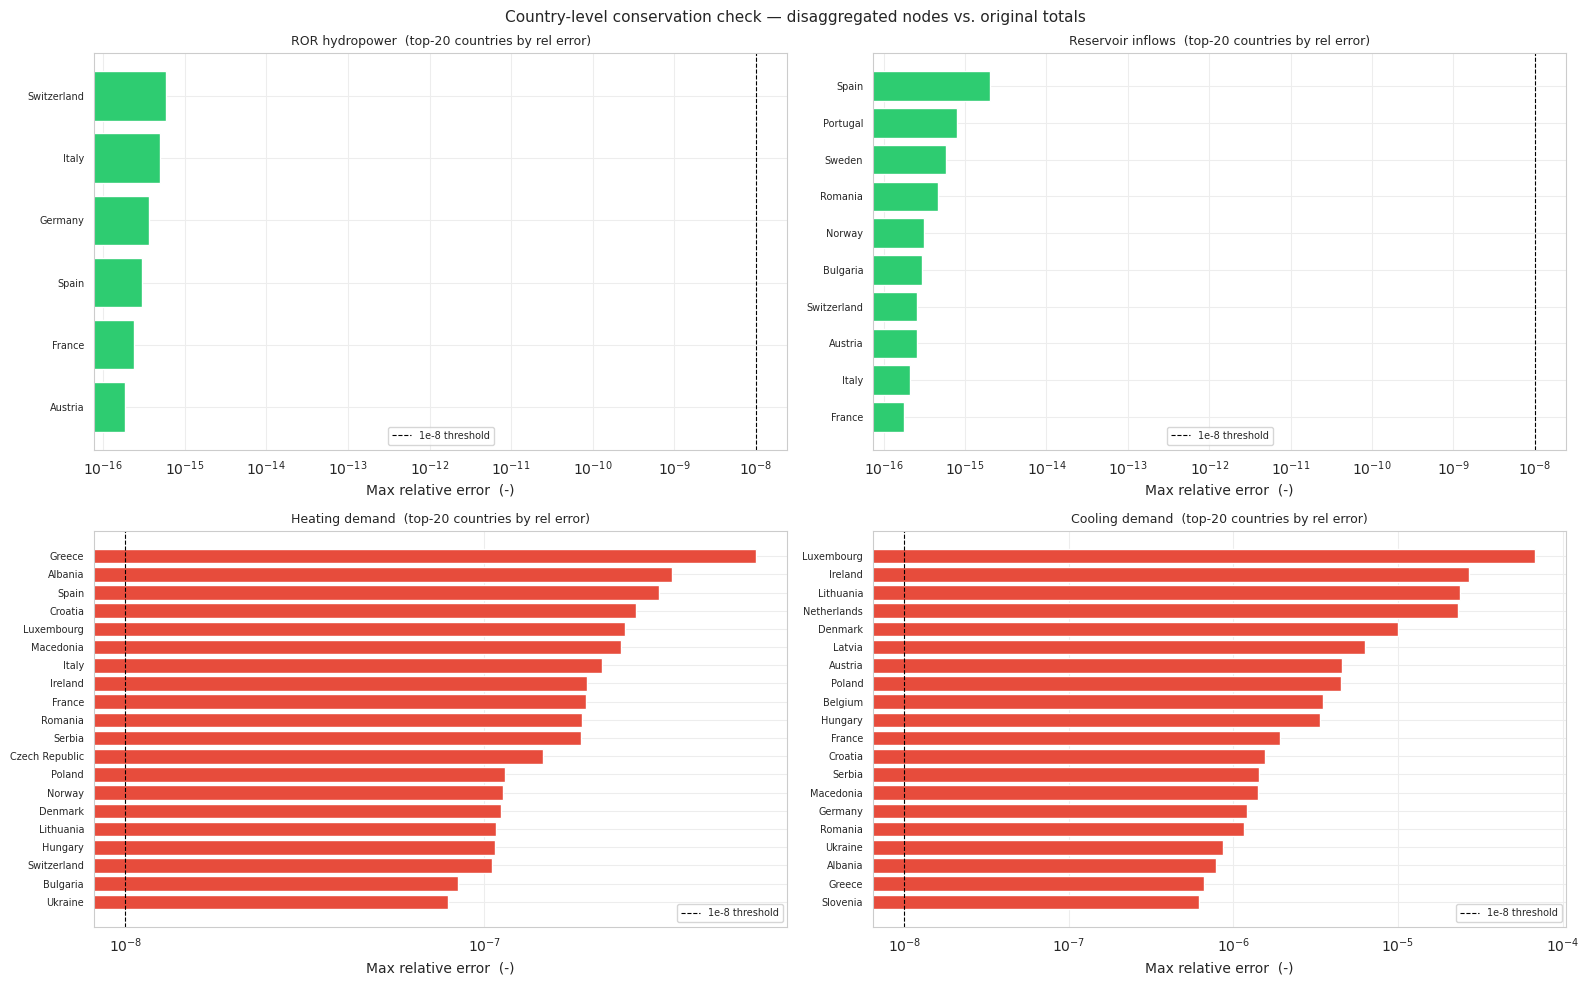

In [39]:

def _validate_conservation(df_nodes, country_ts, id_to_country, label):
    """
    Re-aggregate bus/node-level values back to country level and compare with
    the original country time series at every timestep.

    Parameters
    ----------
    df_nodes      : DataFrame (timesteps × columns)  — disaggregated node values
    country_ts    : DataFrame (countries × timesteps) — original country-level data
    id_to_country : dict  column_label → country_name
    label         : str   display label

    Returns
    -------
    summary   : DataFrame  per-country error statistics, sorted by max_rel_err
    abs_err   : DataFrame  absolute error at every (timestep, country)
    rel_err   : DataFrame  relative error at every (timestep, country)
    """
    # ── Re-aggregate nodes → countries ────────────────────────────────────────
    country_labels = pd.Index(df_nodes.columns).map(lambda c: id_to_country.get(c))
    valid = country_labels.notna()           # numpy bool array
    df_sub = df_nodes.iloc[:, valid].copy()  # iloc accepts numpy bool arrays directly
    df_sub.columns = country_labels[valid]
    df_reconst = df_sub.T.groupby(level=0).sum().T   # (timesteps × countries)

    # ── Align original to the same orientation ────────────────────────────────
    orig = country_ts.T.copy()
    orig.index = pd.to_datetime(orig.index, errors="coerce")
    orig = orig[orig.index.notna()]

    common_countries = df_reconst.columns.intersection(orig.columns)
    common_times     = df_reconst.index.intersection(orig.index)

    r = df_reconst.loc[common_times, common_countries]
    o = orig.loc[common_times, common_countries]

    # ── Errors ────────────────────────────────────────────────────────────────
    abs_err = (r - o).abs()

    # Normalise by each country's mean absolute value (avoids /0 for zero periods)
    scale   = o.abs().mean().replace(0, np.nan)
    rel_err = abs_err / scale

    # ── Summary ───────────────────────────────────────────────────────────────
    summary = pd.DataFrame({
        "max_abs_err":         abs_err.max(),
        "mean_abs_err":        abs_err.mean(),
        "max_rel_err":         rel_err.max(),
        "mean_rel_err":        rel_err.mean(),
        "n_ts_nonzero_err":    (abs_err > 1e-9).sum(),
    }).sort_values("max_rel_err", ascending=False)

    n_ok  = (summary["max_rel_err"] < 1e-8).sum()
    n_tot = len(summary)
    ok_str = "✓ OK" if summary["max_rel_err"].max() < 1e-8 else "✗ values NOT preserved"

    print(f"\n{'─'*60}")
    print(f"  {label}")
    print(f"  Countries compared : {n_tot}  |  timesteps : {len(common_times)}")
    print(f"  Max absolute error : {summary['max_abs_err'].max():.3e}")
    print(f"  Max relative error : {summary['max_rel_err'].max():.3e}  ({ok_str})")
    print(f"  Countries perfectly preserved (rel err < 1e-8) : {n_ok} / {n_tot}")

    if n_ok < n_tot:
        worst = summary.head(5)
        print(f"\n  Worst countries (top 5):")
        print(
            worst[["max_abs_err", "max_rel_err", "n_ts_nonzero_err"]]
            .to_string(float_format=lambda x: f"{x:.3e}")
        )

    return summary, abs_err, rel_err


# ── ROR hydropower ────────────────────────────────────────────────────────────
bus_to_country_ror = (
    node_cap.drop_duplicates("BUS_I").set_index("BUS_I")["Country"].to_dict()
)
summary_ror, abs_err_ror, rel_err_ror = _validate_conservation(
    df_ror_nodes, ror_country_ts, bus_to_country_ror, "ROR hydropower"
)

# ── Reservoir inflows ─────────────────────────────────────────────────────────
bus_to_country_inf = (
    node_cap_inflow.drop_duplicates("BUS_I").set_index("BUS_I")["Country"].to_dict()
)
summary_inf, abs_err_inf, rel_err_inf = _validate_conservation(
    df_inflow_nodes, inflow_country_ts, bus_to_country_inf, "Reservoir inflows"
)

# ── Heating demand ────────────────────────────────────────────────────────────
# node_idx (= row index in gdf_voronoi_nodes after reset_index) → full country name
_node_to_fullname = {
    idx: iso_to_fullname[iso]
    for idx, iso in gdf_voronoi_nodes["COUNTRY"].to_dict().items()
    if iso in iso_to_fullname
}
summary_heat, abs_err_heat, rel_err_heat = _validate_conservation(
    df_heat_nodes, heat_country_ts, _node_to_fullname, "Heating demand"
)

# ── Cooling demand ────────────────────────────────────────────────────────────
summary_cool, abs_err_cool, rel_err_cool = _validate_conservation(
    df_cool_nodes, cool_country_ts, _node_to_fullname, "Cooling demand"
)

# ── Visual summary ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.ravel()

for ax, (lbl, summary, rel_err) in zip(axes, [
    ("ROR hydropower",    summary_ror,  rel_err_ror),
    ("Reservoir inflows", summary_inf,  rel_err_inf),
    ("Heating demand",    summary_heat, rel_err_heat),
    ("Cooling demand",    summary_cool, rel_err_cool),
]):
    # Bar chart: max relative error per country (log scale)
    vals = summary["max_rel_err"].dropna().sort_values(ascending=False).head(20)
    colors = ["#e74c3c" if v > 1e-8 else "#2ecc71" for v in vals]
    ax.barh(range(len(vals)), vals.values, color=colors)
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels(vals.index, fontsize=7)
    ax.axvline(1e-8, color="k", ls="--", lw=0.8, label="1e-8 threshold")
    ax.set_xscale("log")
    ax.set_xlabel("Max relative error  (-)")
    ax.set_title(f"{lbl}  (top-20 countries by rel error)", fontsize=9)
    ax.legend(fontsize=7)
    ax.invert_yaxis()

plt.suptitle("Country-level conservation check — disaggregated nodes vs. original totals", fontsize=11)
plt.tight_layout()
plt.show()


In [40]:
# Per-country breakdown (top 10 by max relative error) for each variable
for _label, _summary in [
    ("ROR hydropower",    summary_ror),
    ("Reservoir inflows", summary_inf),
    ("Heating demand",    summary_heat),
    ("Cooling demand",    summary_cool),
]:
    if _summary is None:
        continue
    print(f"\n{_label}  — top countries by max relative error:")
    print(_summary.head(10).to_string(float_format=lambda x: f"{x:.3e}"))


ROR hydropower  — top countries by max relative error:
             max_abs_err  mean_abs_err  max_rel_err  mean_rel_err  n_ts_nonzero_err
Switzerland    2.842e-14     4.976e-15    5.838e-16     1.022e-16                 0
Italy          4.263e-14     7.310e-15    4.937e-16     8.466e-17                 0
Germany        1.421e-14     4.713e-15    3.620e-16     1.201e-16                 0
Spain          7.105e-15     2.907e-15    3.020e-16     1.235e-16                 0
France         2.842e-14     4.400e-15    2.360e-16     3.654e-17                 0
Austria        1.421e-14     2.974e-15    1.872e-16     3.917e-17                 0

Reservoir inflows  — top countries by max relative error:
             max_abs_err  mean_abs_err  max_rel_err  mean_rel_err  n_ts_nonzero_err
Spain          9.095e-13     3.211e-14    2.019e-15     7.129e-17                 0
Portugal       5.684e-14     4.234e-15    7.883e-16     5.871e-17                 0
Sweden         9.095e-13     1.316e-13    5.8

In [41]:

# ── Switzerland-specific diagnostics  (collaborator feedback) ────────────────
_yr = years[0]   # check first requested year

print(f"\n{'='*60}")
print(f"  Switzerland / {_yr} — issue diagnostics")
print(f"{'='*60}\n")

# Full Voronoi bus sets for Switzerland
_ch_dem_buses  = gdf_voronoi_nodes.loc[gdf_voronoi_nodes["COUNTRY"] == "CH", "BUS_I"].tolist()
_ch_wind_buses = gdf_voronoi_nodes_wind.loc[gdf_voronoi_nodes_wind["COUNTRY"] == "CH", "BUS_I"].tolist()
_ch_node_idxs  = gdf_voronoi_nodes.index[gdf_voronoi_nodes["COUNTRY"] == "CH"].tolist()

print(f"Voronoi demand nodes (CH) : {len(_ch_dem_buses)}")
print(f"Voronoi wind nodes   (CH) : {len(_ch_wind_buses)}")

_ch_fullname = iso_to_fullname.get("CH", "Switzerland")

# ── RoR : coverage and annual total ──────────────────────────────────────────
_ch_ror_buses   = [b for b in _ch_dem_buses if b in df_ror_nodes.columns]
_ch_ror_missing = sorted(set(_ch_dem_buses) - set(_ch_ror_buses))
print(f"\n[RoR]")
print(f"  Covered buses : {len(_ch_ror_buses)} / {len(_ch_dem_buses)}")
if _ch_ror_missing:
    print(f"  Missing buses : {_ch_ror_missing[:10]}{'…' if len(_ch_ror_missing) > 10 else ''}")

_yr_ror_cols = [c for c in ror_country_ts.columns if str(_yr) in str(c)]
_ch_ror_raw  = ror_country_ts.loc[_ch_fullname, _yr_ror_cols].sum() if _ch_fullname in ror_country_ts.index else float("nan")
_ch_ror_node = df_ror_nodes[_ch_ror_buses].loc[str(_yr)].sum().sum() if _ch_ror_buses else 0.0
print(f"  Country total (raw CSV, {_yr})   : {_ch_ror_raw:.3f}  [CSV units × timesteps]")
print(f"  Node total    (after disagg, {_yr}): {_ch_ror_node:.3f}")
_ror_loss = 100 * (1 - _ch_ror_node / _ch_ror_raw) if _ch_ror_raw else float("nan")
print(f"  Loss to disaggregation           : {_ror_loss:.2f}%  (should be ~0)")

# ── Inflow : coverage ─────────────────────────────────────────────────────────
_ch_inf_buses   = [b for b in _ch_dem_buses if b in df_inflow_nodes.columns]
_ch_inf_missing = sorted(set(_ch_dem_buses) - set(_ch_inf_buses))
print(f"\n[Inflow]")
print(f"  Covered buses : {len(_ch_inf_buses)} / {len(_ch_dem_buses)}")
if _ch_inf_missing:
    print(f"  Missing buses : {_ch_inf_missing[:10]}{'…' if len(_ch_inf_missing) > 10 else ''}")

_yr_inf_cols = [c for c in inflow_country_ts.columns if str(_yr) in str(c)]
_ch_inf_raw  = inflow_country_ts.loc[_ch_fullname, _yr_inf_cols].sum() if _ch_fullname in inflow_country_ts.index else float("nan")
_ch_inf_node = df_inflow_nodes[_ch_inf_buses].loc[str(_yr)].sum().sum() if _ch_inf_buses else 0.0
print(f"  Country total (raw CSV, {_yr})   : {_ch_inf_raw:.3f}")
print(f"  Node total    (after disagg, {_yr}): {_ch_inf_node:.3f}")

# ── Heating demand ────────────────────────────────────────────────────────────
_ch_heat_nodes = [n for n in _ch_node_idxs if n in df_heat_nodes.columns]
_yr_heat_cols  = [c for c in heat_country_ts.columns if str(_yr) in str(c)]
_ch_heat_raw   = heat_country_ts.loc[_ch_fullname, _yr_heat_cols].sum() if _ch_fullname in heat_country_ts.index else float("nan")
_ch_heat_node  = df_heat_nodes[_ch_heat_nodes].loc[str(_yr)].sum().sum() if _ch_heat_nodes else 0.0
print(f"\n[Heating demand]")
print(f"  Country total (raw CSV, {_yr})   : {_ch_heat_raw:.3f}")
print(f"  Node total    (after disagg, {_yr}): {_ch_heat_node:.3f}")

# ── Cooling demand : check for zeros ─────────────────────────────────────────
_ch_cool_nodes = [n for n in _ch_node_idxs if n in df_cool_nodes.columns]
_yr_cool_cols  = [c for c in cool_country_ts.columns if str(_yr) in str(c)]
print(f"\n[Cooling demand]")
if _ch_fullname in cool_country_ts.index:
    _ch_cool_ts  = cool_country_ts.loc[_ch_fullname, _yr_cool_cols]
    _n_nz        = (_ch_cool_ts.abs() > 1e-9).sum()
    _ch_cool_raw = _ch_cool_ts.sum()
    print(f"  Country total (raw CSV, {_yr})   : {_ch_cool_raw:.3f}")
    print(f"  Non-zero timesteps : {_n_nz} / {len(_ch_cool_ts)}")
else:
    print(f"  '{_ch_fullname}' NOT FOUND in cooling CSV.")
    print(f"  Available names : {list(cool_country_ts.index[:15])}")

_ch_cool_raw_total = cool_country_ts.loc[_ch_fullname, _yr_cool_cols].sum() if _ch_fullname in cool_country_ts.index else 0.0
_ch_cool_node = df_cool_nodes[_ch_cool_nodes].loc[str(_yr)].sum().sum() if _ch_cool_nodes else 0.0
print(f"  Node total    (after disagg, {_yr}): {_ch_cool_node:.3f}")



  Switzerland / 2040 — issue diagnostics

Voronoi demand nodes (CH) : 153
Voronoi wind nodes   (CH) : 153

[RoR]
  Covered buses : 124 / 153
  Missing buses : [407, 411, 412, 414, 418, 437, 454, 458, 466, 471]…
  Country total (raw CSV, 2040)   : 19949.832  [CSV units × timesteps]
  Node total    (after disagg, 2040): 19949.832
  Loss to disaggregation           : 0.00%  (should be ~0)

[Inflow]
  Covered buses : 58 / 153
  Missing buses : [401, 402, 403, 411, 412, 414, 416, 418, 419, 420]…
  Country total (raw CSV, 2040)   : 25315.335
  Node total    (after disagg, 2040): 25315.335

[Heating demand]
  Country total (raw CSV, 2040)   : 15756.670
  Node total    (after disagg, 2040): 15756.670

[Cooling demand]
  Country total (raw CSV, 2040)   : 0.000
  Non-zero timesteps : 0 / 2920
  Node total    (after disagg, 2040): 0.000


# Node choropleth visualisation

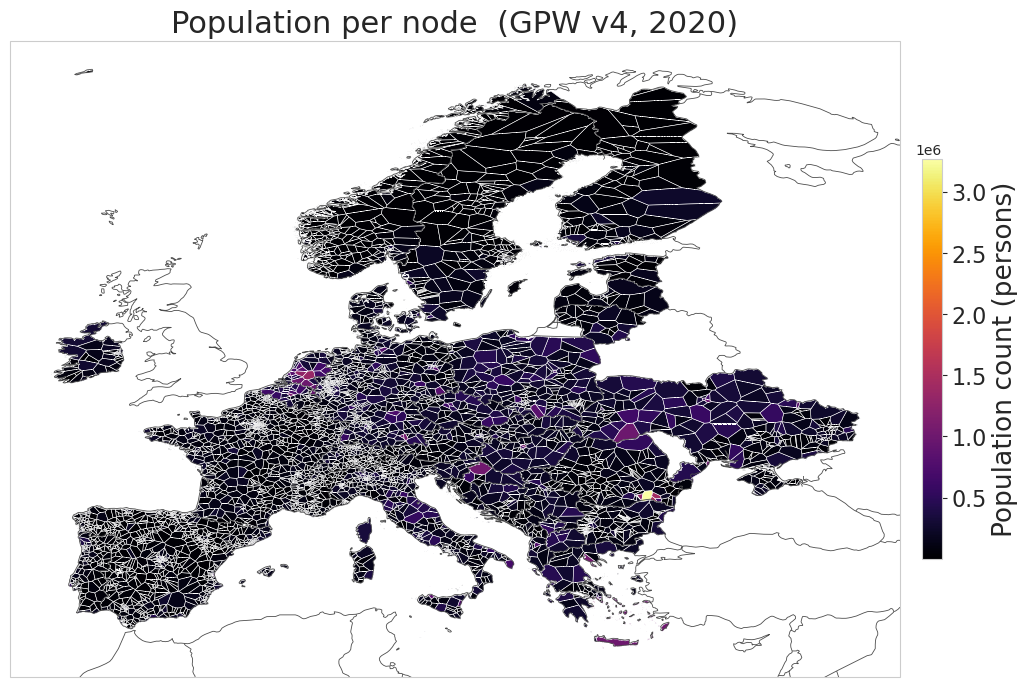

In [42]:
# --- Population per node choropleth ---
plot_nodes_choropleth(
    gdf_nodes=gdf_voronoi_nodes,
    data=pop_per_node,
    time_agg=None,
    cmap="inferno",
    label="Population count (persons)",
    title="Population per node  (GPW v4, 2020)",
    figsize=("28cm", "18cm"),
)
plt.show()


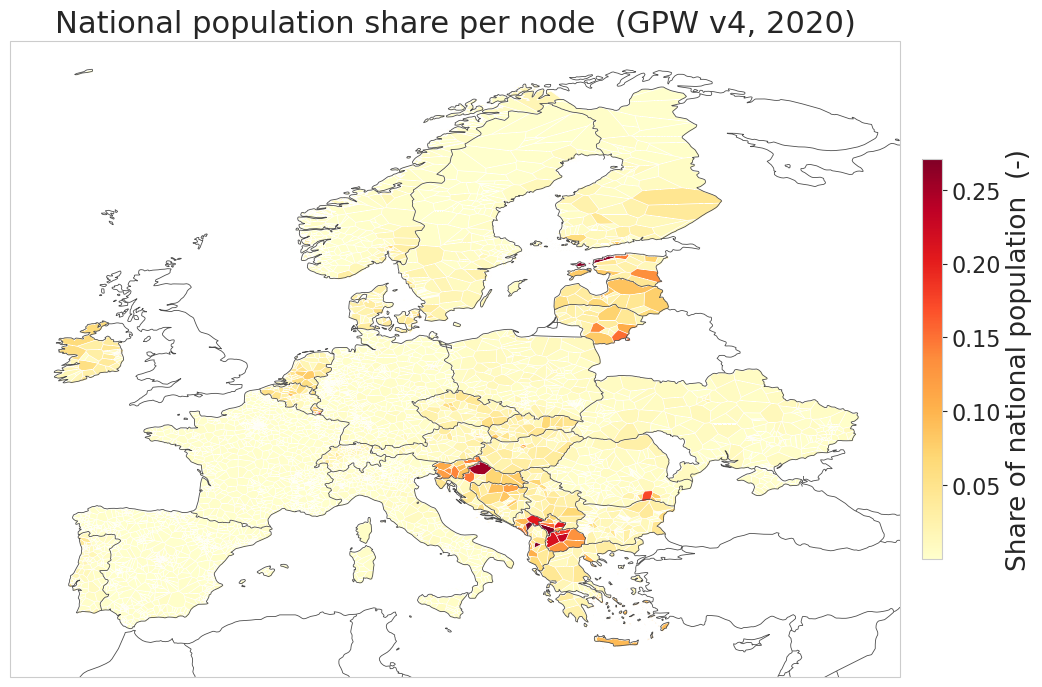

In [43]:
# --- National population share per node choropleth ---
da_pop_share = (
    pop_df.set_index("node_idx")["national_share"]
    .rename_axis("node")
    .to_xarray()
)
da_pop_share.name = "national_share"

plot_nodes_choropleth(
    gdf_nodes=gdf_voronoi_nodes,
    data=da_pop_share,
    time_agg=None,
    cmap="YlOrRd",
    label="Share of national population  (-)",
    title="National population share per node  (GPW v4, 2020)",
    figsize=("28cm", "18cm"),
)
plt.show()


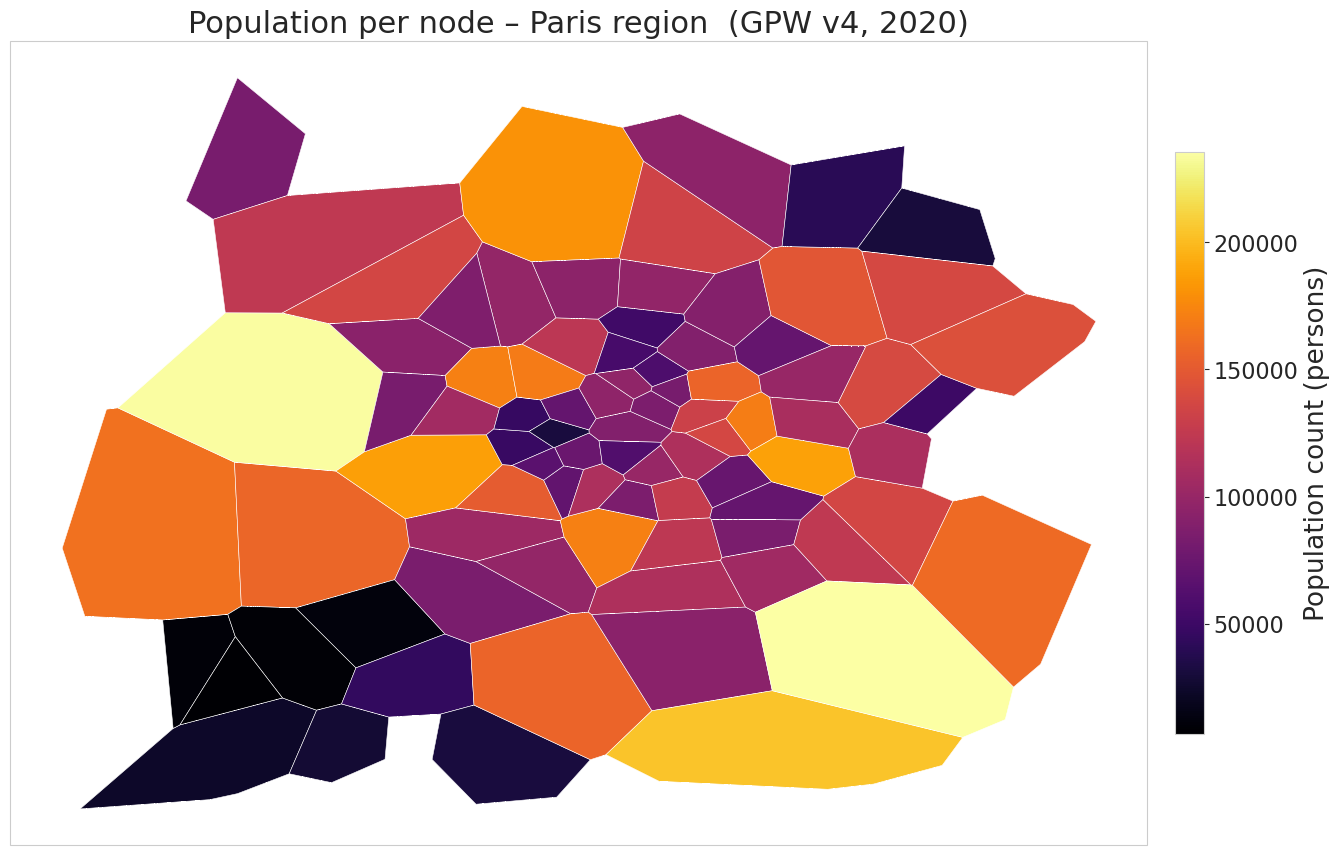

In [44]:
# --- Population per node – Paris region zoom ---
# Bounding box: roughly Île-de-France + surrounding regions
paris_lon = (2.1, 2.5)
paris_lat = (48.7, 49.0)

gdf_paris = gdf_voronoi_nodes.cx[paris_lon[0]:paris_lon[1], paris_lat[0]:paris_lat[1]]

plot_nodes_choropleth(
    gdf_nodes=gdf_paris,
    data=pop_per_node.sel(node=gdf_paris.index.values),
    time_agg=None,
    cmap="inferno",
    label="Population count (persons)",
    title="Population per node – Paris region  (GPW v4, 2020)",
    figsize=(14, 10),
)
plt.show()

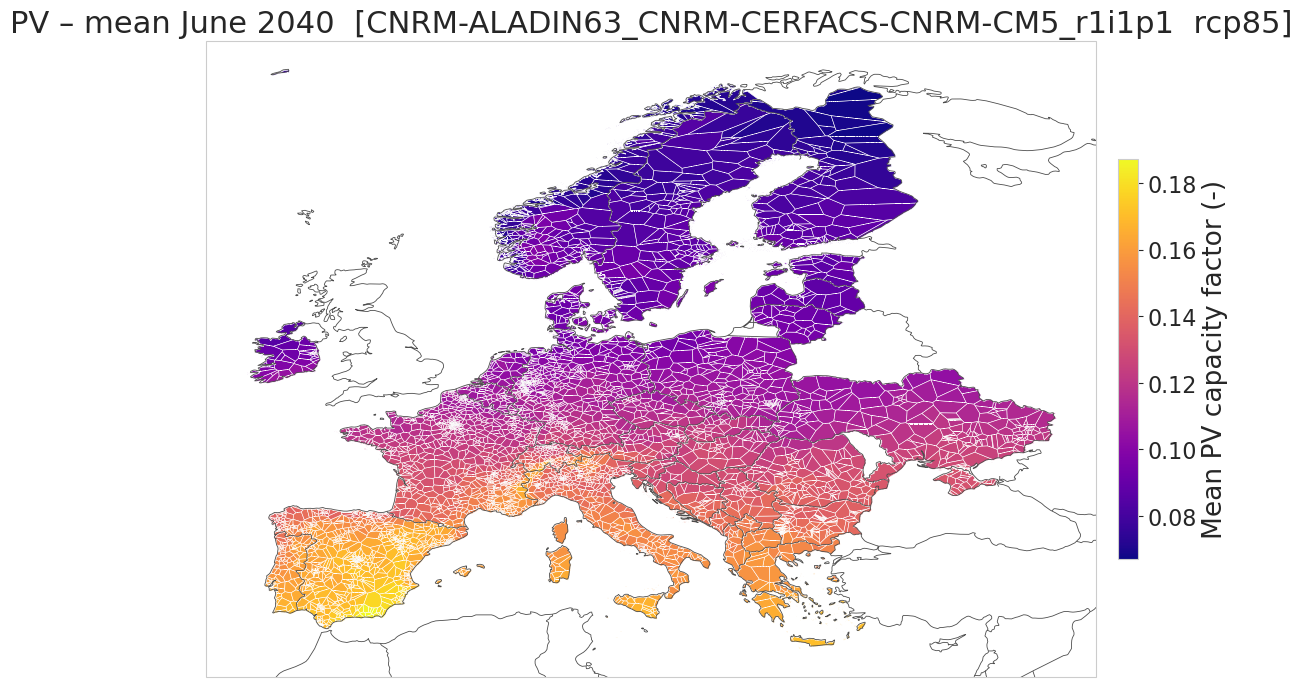

In [45]:
# --- PV: mean capacity factor per node (all June 2040) ---
plot_nodes_choropleth(
    gdf_nodes=gdf_voronoi_nodes,
    data=ds_pv_grouped,  # Dataset with 'node' dim from groupby
    time_agg="mean",  # aggregate over the time dimension
    cmap="plasma",
    label="Mean PV capacity factor (-)",
    title=f"PV – mean June 2040  [{climate_model}  {climate_scenario}]",
    figsize=("28cm", "18cm"),
)
plt.show()

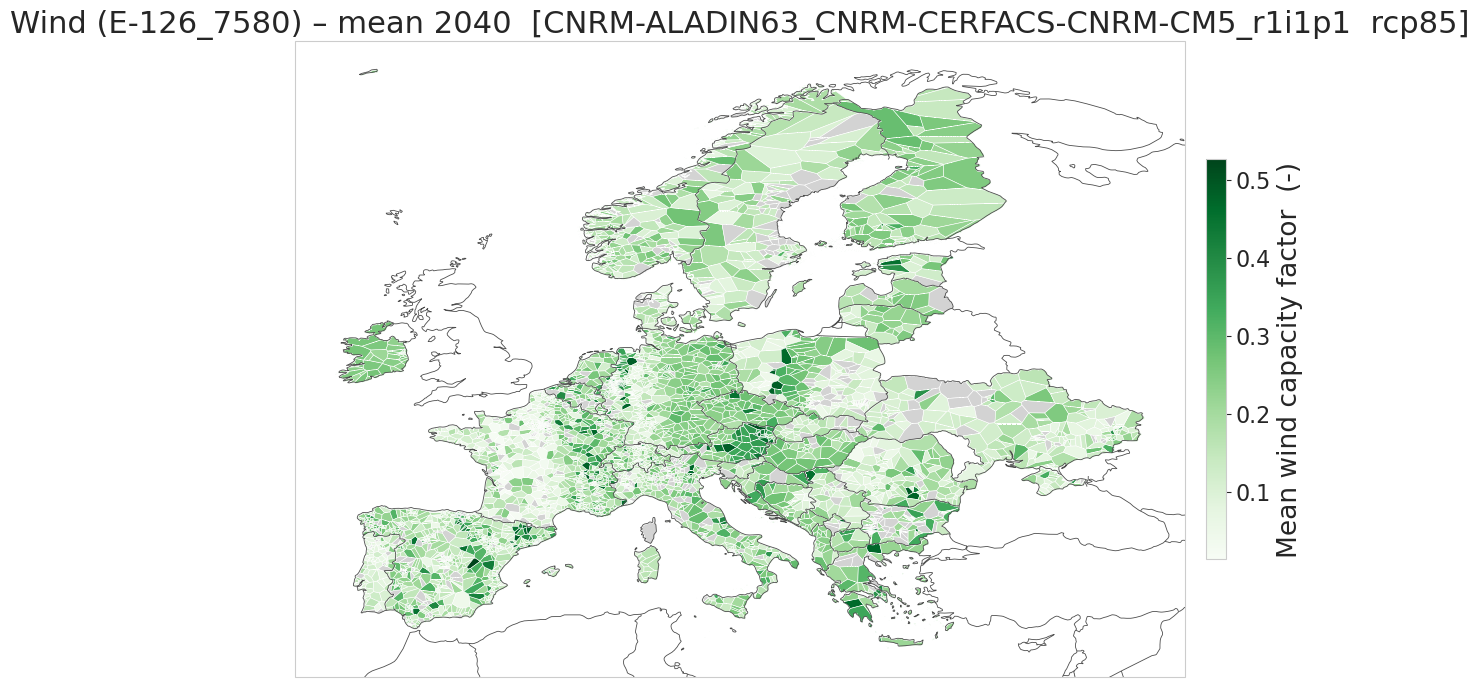

In [46]:
# --- Wind power: mean capacity factor per node ---
plot_nodes_choropleth(
    gdf_nodes=gdf_voronoi_nodes,
    data=ds_wind_grouped,
    time_agg="mean",
    cmap="Greens",
    label="Mean wind capacity factor  (-)",
    title=f"Wind ({wind_turbine}) – mean 2040  [{climate_model}  {climate_scenario}]",
    figsize=("28cm", "18cm"),
)
plt.show()

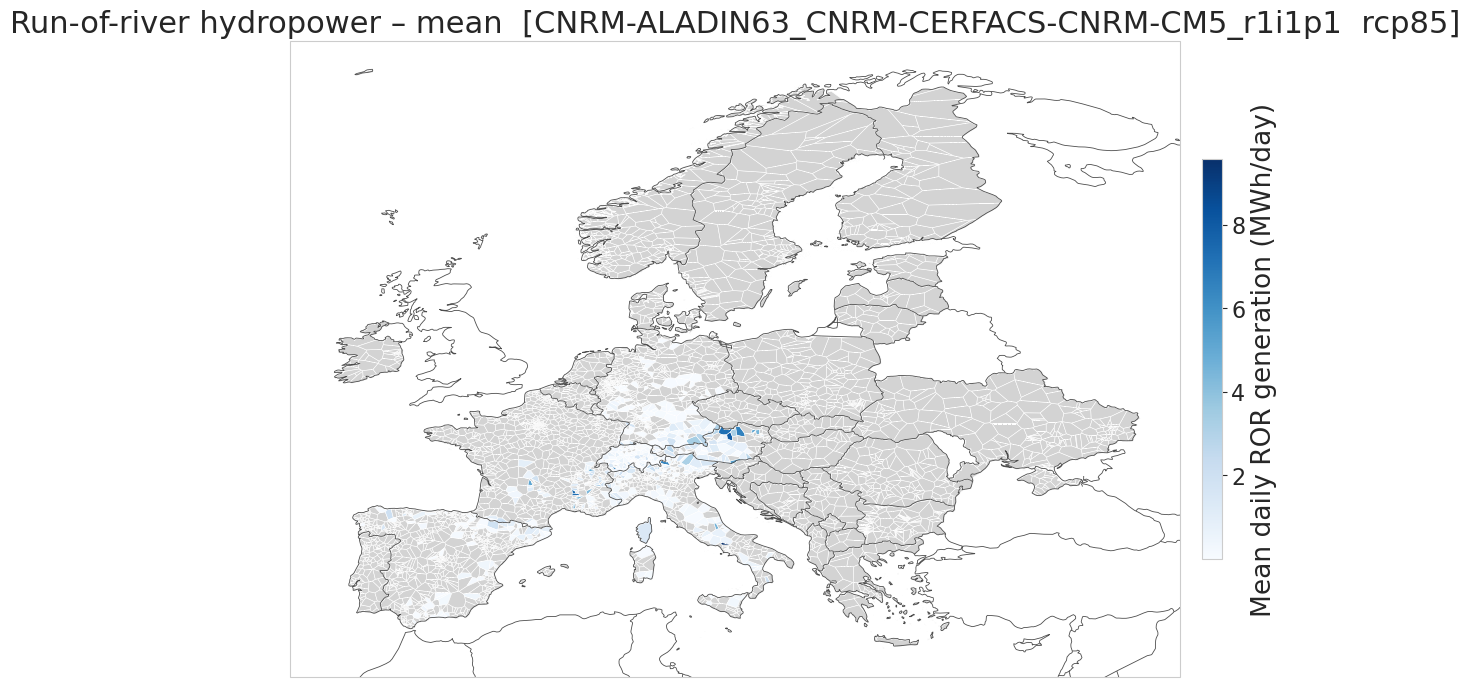

In [47]:
# --- Convert df_ror_nodes (time × BUS_I) → xarray DataArray with node indices ---
# plot_nodes_choropleth expects integer node indices matching gdf_voronoi_nodes row positions

bus_to_node_idx = {bus_i: idx for idx, bus_i in enumerate(gdf_voronoi_nodes["BUS_I"])}

da_ror_nodes = (
    df_ror_nodes
    .rename(columns=bus_to_node_idx)   # BUS_I values → 0-based row indices
    .mean(axis=0)                       # mean over time
    .rename_axis("node")
    .to_xarray()
)
da_ror_nodes.name = "ror_generation"

plot_nodes_choropleth(
    gdf_nodes=gdf_voronoi_nodes,
    data=da_ror_nodes,
    time_agg=None,
    cmap="Blues",
    label="Mean daily ROR generation (MWh/day)",
    title=f"Run-of-river hydropower – mean  [{climate_model}  {climate_scenario}]",
    figsize=("28cm", "18cm"),
)
plt.show()


In [48]:
df_ror_nodes.loc[:, [v for v in gdf_voronoi_nodes[gdf_voronoi_nodes["COUNTRY"] == "CH"]["BUS_I"] if v in df_ror_nodes.columns]].sum().sum()

35541.69615337599

In [49]:
gdf_voronoi_nodes[gdf_voronoi_nodes["COUNTRY"] == "CH"]["BUS_I"].values

array([401, 402, 403, 407, 411, 412, 413, 414, 416, 418, 419, 420, 421,
       423, 424, 425, 426, 427, 428, 429, 430, 431, 434, 436, 437, 438,
       439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 452, 453,
       454, 455, 456, 457, 458, 459, 461, 462, 463, 464, 465, 466, 469,
       470, 471, 472, 473, 474, 475, 476, 477, 478, 480, 482, 483, 484,
       485, 486, 487, 488, 489, 490, 491, 492, 493, 495, 496, 497, 498,
       499, 500, 501, 502, 503, 504, 505, 507, 508, 509, 511, 512, 513,
       515, 516, 517, 518, 519, 521, 522, 523, 524, 525, 526, 527, 528,
       529, 530, 531, 532, 533, 534, 536, 537, 538, 539, 540, 541, 542,
       544, 545, 547, 548, 549, 550, 552, 553, 554, 555, 556, 557, 558,
       559, 560, 562, 563, 564, 565, 566, 568, 569, 570, 571, 572, 573,
       575, 576, 577, 578, 579, 580, 581, 582, 583, 584])

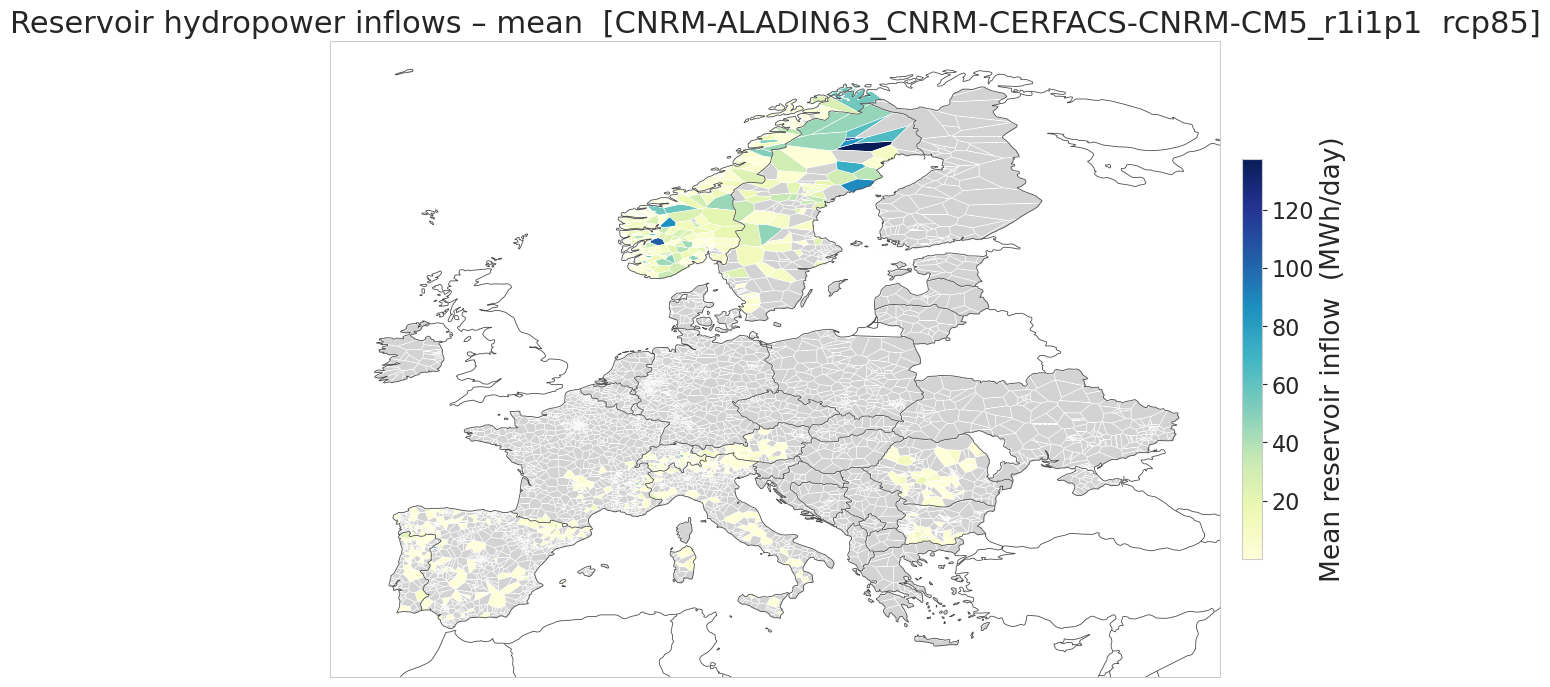

In [50]:
# --- Visualise: mean reservoir inflow per node ---
bus_to_node_idx = {bus_i: idx for idx, bus_i in enumerate(gdf_voronoi_nodes["BUS_I"])}

da_inflow_nodes = (
    df_inflow_nodes
    .rename(columns=bus_to_node_idx)
    .mean(axis=0)
    .rename_axis("node")
    .to_xarray()
)
da_inflow_nodes.name = "inflow"

plot_nodes_choropleth(
    gdf_nodes=gdf_voronoi_nodes,
    data=da_inflow_nodes,
    time_agg=None,
    cmap="YlGnBu",
    label="Mean reservoir inflow  (MWh/day)",
    title=f"Reservoir hydropower inflows – mean  [{climate_model}  {climate_scenario}]",
    figsize=("28cm", "18cm"),
)
plt.show()


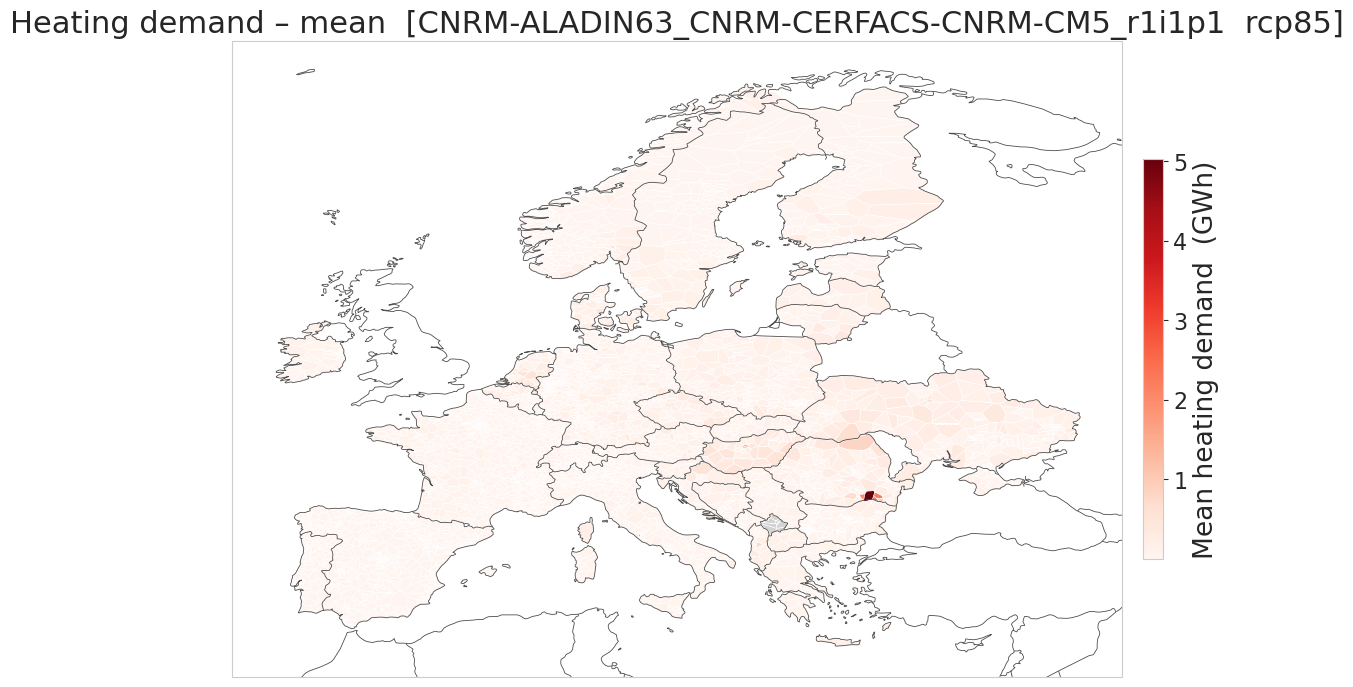

In [51]:
# --- Heating demand: mean per node choropleth ---
da_heat_nodes = (
    df_heat_nodes
    .mean(axis=0)           # mean over time
    .rename_axis("node")
    .to_xarray()
)
da_heat_nodes.name = "heating_demand"

plot_nodes_choropleth(
    gdf_nodes=gdf_voronoi_nodes,
    data=da_heat_nodes,
    time_agg=None,
    cmap="Reds",
    label="Mean heating demand  (GWh)",
    title=f"Heating demand – mean  [{climate_model}  {climate_scenario}]",
    figsize=("28cm", "18cm"),
)
plt.show()


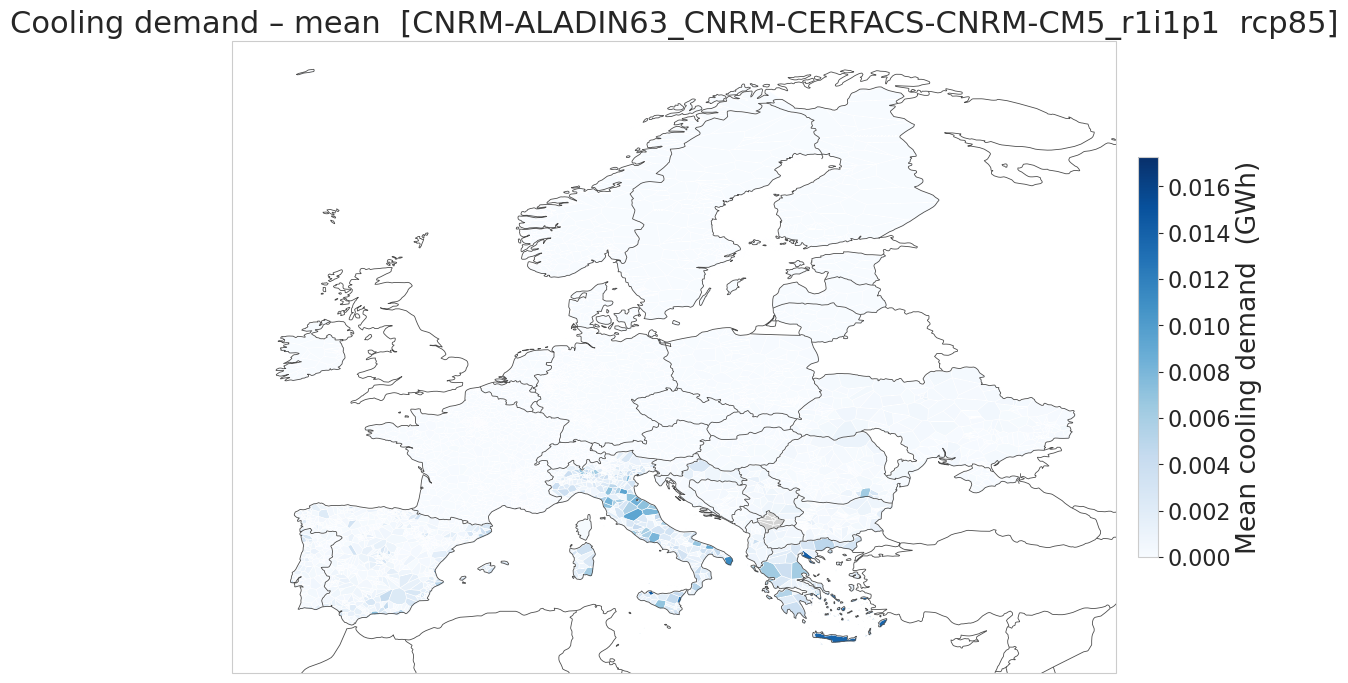

In [52]:
# --- Cooling demand: mean per node choropleth ---
da_cool_nodes = (
    df_cool_nodes
    .mean(axis=0)           # mean over time
    .rename_axis("node")
    .to_xarray()
)
da_cool_nodes.name = "cooling_demand"

plot_nodes_choropleth(
    gdf_nodes=gdf_voronoi_nodes,
    data=da_cool_nodes,
    time_agg=None,
    cmap="Blues",
    label="Mean cooling demand  (GWh)",
    title=f"Cooling demand – mean  [{climate_model}  {climate_scenario}]",
    figsize=("28cm", "18cm"),
)
plt.show()


# Bringing everything together

In [53]:

# ── Helper functions ──────────────────────────────────────────────────────────
def _fmt_bus(val):
    """Format BUS_I: drop trailing '.0' for whole-number floats."""
    try:
        f = float(val)
        return str(int(f)) if f == int(f) else str(f)
    except (ValueError, TypeError):
        return str(val)

def _ds_to_df(ds, prefix, id_map):
    """Grouped xarray Dataset (time × node) → flat DataFrame with prefixed columns."""
    var = list(ds.data_vars)[0]
    da  = ds[var]
    return pd.DataFrame(
        da.values,
        index=pd.to_datetime(da.time.values),
        columns=[f"{prefix}.{_fmt_bus(id_map[int(n)])}" for n in da.node.values],
    ).rename_axis("time")

node_to_bus   = gdf_voronoi_nodes["BUS_I"].to_dict()
node_to_bus_w = gdf_voronoi_nodes_wind["BUS_I"].to_dict()

# Pre-compute the full expected bus lists (formatted) for each profile type
# These define every column that the energy model expects to find in the output.
_all_dem_bus  = [_fmt_bus(b) for b in gdf_voronoi_nodes["BUS_I"]]
_all_wind_bus = [_fmt_bus(b) for b in gdf_voronoi_nodes_wind["BUS_I"]]

# ── Per-year loop ─────────────────────────────────────────────────────────────
for year in years:
    print(f"\n{'='*60}\n  Assembling profiles for {year}\n{'='*60}\n")

    # ── Reference hourly index (365-day, no leap) ──────────────────────────────
    _wind_y = ds_wind_grouped.sel(time=str(year))
    if _wind_y.time.size == 0:
        print(f"  WARNING: ds_wind_grouped has no data for {year} — skipping.")
        continue
    var_wind = list(_wind_y.data_vars)[0]
    hourly_idx = pd.to_datetime(_wind_y[var_wind].time.values)
    leap_mask  = (hourly_idx.month == 2) & (hourly_idx.day == 29)
    if leap_mask.any():
        print(f"  Dropping {leap_mask.sum()} leap-day hour(s).")
    hourly_idx = hourly_idx[~leap_mask]
    print(f"  Reference grid: {hourly_idx[0]} → {hourly_idx[-1]}  ({len(hourly_idx):,} steps)")

    # ── 1. PV ──────────────────────────────────────────────────────────────────
    _pv_raw = _ds_to_df(
        ds_pv_grouped.sel(time=str(year)), "profile.generation.solar", node_to_bus
    )
    _pv_raw.index -= pd.Timedelta("30min")
    df_pv_1h = _pv_raw.reindex(hourly_idx)

    # ── 2. Wind ────────────────────────────────────────────────────────────────
    df_wind_1h = _ds_to_df(
        _wind_y, "profile.generation.wind", node_to_bus_w
    ).reindex(hourly_idx)

    # ── 3. ROR hydro  (daily → uniform hourly) ────────────────────────────────
    _ror = df_ror_nodes.loc[str(year)].copy()
    _ror.index = _ror.index.normalize()
    df_ror_1h = (
        _ror.reindex(hourly_idx, method="ffill") / 24
    ).rename(columns=lambda c: f"profile.generation.ror.{_fmt_bus(c)}")

    # ── 4. Reservoir inflows  (weekly → uniform hourly) ───────────────────────
    _inf = df_inflow_nodes.loc[str(year)].sort_index().copy()
    _td  = _inf.index.to_series().diff().shift(-1)
    _td.iloc[-1] = _td.iloc[-2]
    df_inflow_1h = (
        _inf.div(_td.dt.total_seconds() / 3600, axis=0)
        .reindex(hourly_idx, method="ffill").ffill().bfill()
    ).rename(columns=lambda c: f"profile.generation.inflow.{_fmt_bus(c)}")

    # ── 5. Heating demand  (3-hourly → hourly, linear) ────────────────────────
    df_heat_1h = (
        df_heat_nodes.loc[str(year)].resample("h").asfreq().interpolate("time")
        .reindex(hourly_idx)
        .rename(columns=lambda c: f"profile.demand.heating.{_fmt_bus(node_to_bus[int(c)])}")
    )

    # ── 6. Cooling demand  (3-hourly → hourly, linear) ────────────────────────
    df_cool_1h = (
        df_cool_nodes.loc[str(year)].resample("h").asfreq().interpolate("time")
        .reindex(hourly_idx)
        .rename(columns=lambda c: f"profile.demand.cooling.{_fmt_bus(node_to_bus[int(c)])}")
    )

    # ── 7. Concatenate ────────────────────────────────────────────────────────
    df_profiles_y = pd.concat(
        [df_pv_1h, df_wind_1h, df_ror_1h, df_inflow_1h, df_heat_1h, df_cool_1h],
        axis=1,
    )
    df_profiles_y.index.name = "time"

    # # ── 7b. Ensure every grid bus is present; replace NaN with 0 ─────────────
    # # Buses that have no plants / fall outside the spatial mask are absent from
    # # the component DataFrames above.  Energy models expect a column for every
    # # bus even when the profile is zero (e.g. a bus with no RoR plants).
    # for _pfx, _bus_list in [
    #     ("profile.generation.solar",  _all_dem_bus),
    #     ("profile.generation.wind",   _all_wind_bus),
    #     ("profile.generation.ror",    _all_dem_bus),
    #     ("profile.generation.inflow", _all_dem_bus),
    #     ("profile.demand.heating",    _all_dem_bus),
    #     ("profile.demand.cooling",    _all_dem_bus),
    # ]:
    #     _expected = [f"{_pfx}.{b}" for b in _bus_list]
    #     _missing  = [c for c in _expected if c not in df_profiles_y.columns]
    #     if _missing:
    #         df_profiles_y[_missing] = 0.0
    #         print(f"  Added {len(_missing):,} zero columns for {_pfx}")

    # # Fill any remaining NaN (spatial gaps, reindex misses) with 0
    # _n_nan = int(df_profiles_y.isna().sum().sum())
    # if _n_nan:
    #     print(f"  Filling {_n_nan:,} NaN → 0  (masked / out-of-domain cells)")
    # df_profiles_y = df_profiles_y.fillna(0.0)

    print(f"  Profile table : {df_profiles_y.shape[0]:,} timesteps × {df_profiles_y.shape[1]:,} columns")
    print(f"  Time range    : {df_profiles_y.index[0]}  →  {df_profiles_y.index[-1]}")
    for pfx in [
        "profile.generation.solar", "profile.generation.wind",
        "profile.generation.ror",   "profile.generation.inflow",
        "profile.demand.heating",   "profile.demand.cooling",
    ]:
        cols = df_profiles_y.columns[df_profiles_y.columns.str.startswith(pfx)]
        zero_pct = (df_profiles_y[cols] == 0).mean().mean() * 100
        print(f"    {pfx:<35s}: {len(cols):>5} cols  (zero: {zero_pct:.1f}%)")

    # ── 8. Save ───────────────────────────────────────────────────────────────
    output_path = (
        path_data_recipe / f"profiles_{climate_model}_{climate_scenario}_{year}.h5"
    )
    df_profiles_y.to_hdf(output_path, key="profiles", mode="w", complevel=5, complib="blosc")
    print(f"\n  Saved  →  {output_path}  ({output_path.stat().st_size / 1e6:.1f} MB)")

# Keep last year's result available for the NaN audit cell below
df_profiles = df_profiles_y
print(f"\nDone — {len(years)} year(s) processed.")



  Assembling profiles for 2040

  Dropping 24 leap-day hour(s).
  Reference grid: 2040-01-01 00:00:00 → 2040-12-31 23:00:00  (8,760 steps)
  Profile table : 8,760 timesteps × 21,946 columns
  Time range    : 2040-01-01 00:00:00  →  2040-12-31 23:00:00
    profile.generation.solar           :  4835 cols  (zero: 52.0%)
    profile.generation.wind            :  4899 cols  (zero: 0.5%)
    profile.generation.ror             :   565 cols  (zero: 0.0%)
    profile.generation.inflow          :   701 cols  (zero: 0.4%)
    profile.demand.heating             :  5473 cols  (zero: 8.4%)
    profile.demand.cooling             :  5473 cols  (zero: 72.9%)


ImportError: Pandas requires version '3.10.1' or newer of 'tables' (version '3.9.2' currently installed).